In [1]:

# CELL 1: Install FinSight AI dependencies

%pip -q install pymupdf pandas numpy scikit-learn matplotlib seaborn \
    transformers torch sentence-transformers faiss-cpu


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 79.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 66.4 MB/s eta 0:00:00


In [2]:

# CELL 2: Import libraries and configure the environment

import os
import re
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fitz  # PyMuPDF

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display, Markdown

import torch

warnings.filterwarnings("ignore")
np.random.seed(42)

# Check available hardware
device = "cuda" if torch.cuda.is_available() else "cpu"

print("FinSight AI environment initialized successfully!")
print("PyTorch version:", torch.__version__)
print("Device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU. You can enable a GPU under Runtime > Change runtime type.")


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


FinSight AI environment initialized successfully!
PyTorch version: 2.11.0+cpu
Device: cpu
Running on CPU. You can enable a GPU under Runtime > Change runtime type.


In [7]:

# CELL 3: Download Financial PhraseBank from GitHub

import pandas as pd
import requests
from io import StringIO

urls = [
    "https://raw.githubusercontent.com/maxwellsarpong/NLP-financial-text-processing-dataset/master/Sentences_50Agree.txt",
    "https://raw.githubusercontent.com/maxwellsarpong/NLP-financial-text-processing-dataset/main/Sentences_50Agree.txt"
]

sentiment_data = None
last_error = None

for url in urls:
    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()

        rows = []
        for line in response.text.splitlines():
            if "@" in line:
                sentence, label = line.rsplit("@", 1)
                rows.append({
                    "sentence": sentence.strip(),
                    "sentiment": label.strip().lower()
                })

        if rows:
            sentiment_data = pd.DataFrame(rows)
            break

    except Exception as e:
        last_error = e

if sentiment_data is None or sentiment_data.empty:
    raise RuntimeError(f"Dataset download failed: {last_error}")

sentiment_data = sentiment_data.drop_duplicates().reset_index(drop=True)

print("Dataset downloaded successfully!")
print("Total records:", len(sentiment_data))
print("\nSentiment distribution:")
print(sentiment_data["sentiment"].value_counts())

display(sentiment_data.head(10))


Dataset downloaded successfully!
Total records: 4840

Sentiment distribution:
sentiment
neutral     2873
positive    1363
negative     604
Name: count, dtype: int64


,sentence,sentiment
0,"According to Gran , the company has no plans t...",neutral
1,Technopolis plans to develop in stages an area...,neutral
2,The international electronic industry company ...,negative
3,With the new production plant the company woul...,positive
4,According to the company 's updated strategy f...,positive
5,FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is ag...,positive
6,"For the last quarter of 2010 , Componenta 's n...",positive
7,"In the third quarter of 2010 , net sales incre...",positive
8,Operating profit rose to EUR 13.1 mn from EUR ...,positive
9,"Operating profit totalled EUR 21.1 mn , up fro...",positive


Dataset shape: (4840, 2)

Missing values:
sentence     0
sentiment    0
dtype: int64

Sentiment labels:
sentiment
neutral     2873
positive    1363
negative     604
Name: count, dtype: int64


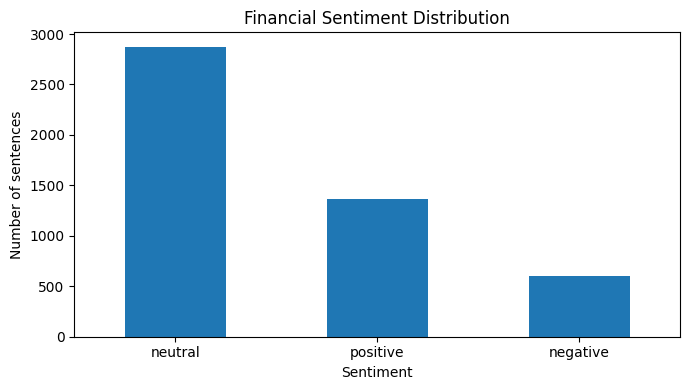

,sentence,sentiment
0,"According to Gran , the company has no plans t...",neutral
1,Technopolis plans to develop in stages an area...,neutral
2,The international electronic industry company ...,negative
3,With the new production plant the company woul...,positive
4,According to the company 's updated strategy f...,positive
5,FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is ag...,positive
6,"For the last quarter of 2010 , Componenta 's n...",positive
7,"In the third quarter of 2010 , net sales incre...",positive
8,Operating profit rose to EUR 13.1 mn from EUR ...,positive
9,"Operating profit totalled EUR 21.1 mn , up fro...",positive


In [8]:

# CELL 4: Clean and explore Financial PhraseBank

import pandas as pd
import matplotlib.pyplot as plt

# Confirm Cell 3 loaded the dataset
if "sentiment_data" not in globals() or sentiment_data is None:
    raise ValueError("Run Cell 3 successfully before running Cell 4.")

# Check required columns
required_columns = {"sentence", "sentiment"}

if not required_columns.issubset(sentiment_data.columns):
    raise ValueError(
        f"Missing required columns: {required_columns - set(sentiment_data.columns)}"
    )

# Keep only the required columns
sentiment_data = sentiment_data[["sentence", "sentiment"]].copy()

# Clean text and labels
sentiment_data["sentence"] = (
    sentiment_data["sentence"].astype(str).str.strip()
)
sentiment_data["sentiment"] = (
    sentiment_data["sentiment"].astype(str).str.strip().str.lower()
)

# Remove empty, missing, and duplicate records
sentiment_data = sentiment_data.dropna()
sentiment_data = sentiment_data[
    (sentiment_data["sentence"] != "") &
    (sentiment_data["sentiment"] != "")
]
sentiment_data = sentiment_data.drop_duplicates().reset_index(drop=True)

# Check labels
print("Dataset shape:", sentiment_data.shape)
print("\nMissing values:")
print(sentiment_data.isnull().sum())

print("\nSentiment labels:")
print(sentiment_data["sentiment"].value_counts())

# Plot label distribution
sentiment_data["sentiment"].value_counts().plot(
    kind="bar", figsize=(7, 4)
)

plt.title("Financial Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of sentences")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Display cleaned sample
display(sentiment_data.head(10))


In [9]:

# CELL 5: Convert financial sentences into TF-IDF vectors

from sklearn.feature_extraction.text import TfidfVectorizer

# Confirm the cleaned dataset exists
if "sentiment_data" not in globals() or sentiment_data.empty:
    raise ValueError("Run Cells 3 and 4 successfully before continuing.")

# Initialize TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=10000,
    min_df=2
)

# Learn vocabulary and transform sentences into vectors
X_tfidf = tfidf_vectorizer.fit_transform(
    sentiment_data["sentence"]
)

# Target labels
y = sentiment_data["sentiment"]

print("TF-IDF conversion completed!")
print("Number of sentences:", X_tfidf.shape[0])
print("Number of features:", X_tfidf.shape[1])

# Show a small sample of the vocabulary
print("\nSample vocabulary:")
print(list(tfidf_vectorizer.get_feature_names_out()[:30]))

# Display the first sentence and its non-zero feature values
first_vector = X_tfidf[0].toarray().flatten()
nonzero_indices = first_vector.nonzero()[0]

feature_sample = pd.DataFrame({
    "word_or_phrase": tfidf_vectorizer.get_feature_names_out()[nonzero_indices],
    "tfidf_score": first_vector[nonzero_indices]
}).sort_values("tfidf_score", ascending=False)

print("\nMost important terms in the first sentence:")
display(feature_sample.head(10))


TF-IDF conversion completed!
Number of sentences: 4840
Number of features: 10000

Sample vocabulary:
['00', '00 eet', '00 finnish', '000', '000 2008', '000 2009', '000 alma', '000 chairman', '000 company', '000 corresponding', '000 customers', '000 employees', '000 eur', '000 euro', '000 euros', '000 m2', '000 m3', '000 net', '000 new', '000 people', '000 period', '000 persons', '000 quarter', '000 readers', '000 shares', '000 sq', '000 square', '000 tonnes', '000 tons', '000 usd']

Most important terms in the first sentence:


,word_or_phrase,tfidf_score
3,gran,0.434892
7,production russia,0.434892
2,company plans,0.384028
4,growing,0.336512
5,plans,0.300567
1,company,0.290430
8,russia,0.262092
0,according,0.242738
6,production,0.242315


Training completed successfully!
Test accuracy: 0.7386
Test accuracy percentage: 73.86%

Classification Report:
              precision    recall  f1-score   support

    negative       0.62      0.64      0.63       121
     neutral       0.79      0.85      0.82       575
    positive       0.67      0.54      0.60       272

    accuracy                           0.74       968
   macro avg       0.69      0.68      0.68       968
weighted avg       0.73      0.74      0.73       968



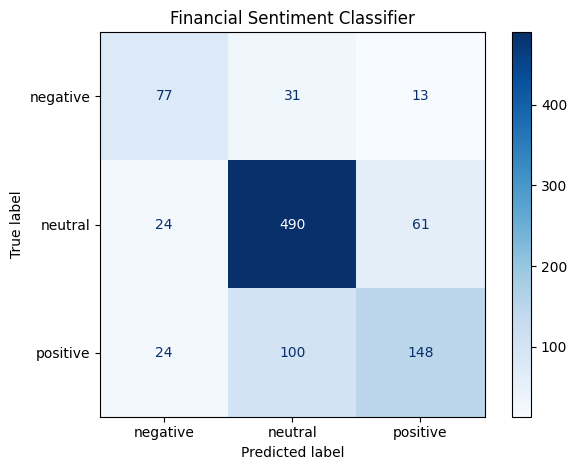

In [10]:

# CELL 6: Train-test split and Logistic Regression model

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Initialize and train the classifier
sentiment_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

sentiment_model.fit(X_train, y_train)

# Generate predictions on unseen test data
y_pred = sentiment_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Training completed successfully!")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Test accuracy percentage: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
labels = sorted(y.unique())

cm = confusion_matrix(y_test, y_pred, labels=labels)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_cm.plot(cmap="Blues", values_format="d")
plt.title("Financial Sentiment Classifier")
plt.tight_layout()
plt.show()


In [11]:

# CELL 7: Predict sentiment for new financial sentences

def predict_financial_sentiment(sentence):
    # Convert the sentence using the SAME TF-IDF vectorizer
    sentence_vector = tfidf_vectorizer.transform([sentence])

    # Predict the sentiment
    predicted_sentiment = sentiment_model.predict(sentence_vector)[0]

    # Get probability estimates
    probabilities = sentiment_model.predict_proba(sentence_vector)[0]

    probability_table = pd.DataFrame({
        "sentiment": sentiment_model.classes_,
        "probability": probabilities
    }).sort_values("probability", ascending=False)

    print("Financial sentence:")
    print(sentence)

    print("\nPredicted sentiment:", predicted_sentiment)

    print("\nModel probability estimates:")
    display(probability_table.reset_index(drop=True))

    return predicted_sentiment


# Test example 1
predict_financial_sentiment(
    "The company reported strong revenue growth and improved profitability."
)

# Test example 2
predict_financial_sentiment(
    "The company suffered significant losses and declining sales."
)

# Test example 3
predict_financial_sentiment(
    "The company announced its annual general meeting for next month."
)


Financial sentence:
The company reported strong revenue growth and improved profitability.

Predicted sentiment: positive

Model probability estimates:


,sentiment,probability
0,positive,0.842496
1,neutral,0.115401
2,negative,0.042103


Financial sentence:
The company suffered significant losses and declining sales.

Predicted sentiment: positive

Model probability estimates:


,sentiment,probability
0,positive,0.426250
1,negative,0.359365
2,neutral,0.214385


Financial sentence:
The company announced its annual general meeting for next month.

Predicted sentiment: neutral

Model probability estimates:


,sentiment,probability
0,neutral,0.698662
1,positive,0.158598
2,negative,0.142740


'neutral'

In [12]:

# CELL 8: Improved Logistic Regression with leakage-safe TF-IDF

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Split RAW text first, before fitting TF-IDF
X_train_text, X_test_text, y_train, y_test = train_test_split(
    sentiment_data["sentence"],
    sentiment_data["sentiment"],
    test_size=0.20,
    random_state=42,
    stratify=sentiment_data["sentiment"]
)

# TF-IDF and classifier are fitted together
baseline_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Tune a small set of meaningful parameters
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "classifier__C": [0.5, 1.0, 2.0]
}

grid_search = GridSearchCV(
    baseline_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_text, y_train)

improved_model = grid_search.best_estimator_
improved_predictions = improved_model.predict(X_test_text)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation macro F1:")
print(round(grid_search.best_score_, 4))

print("\nHeld-out test accuracy:")
print(round(accuracy_score(y_test, improved_predictions), 4))

print("\nHeld-out classification report:")
print(classification_report(
    y_test,
    improved_predictions,
    zero_division=0
))


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'classifier__C': 2.0, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}

Best cross-validation macro F1:
0.6673

Held-out test accuracy:
0.7221

Held-out classification report:
              precision    recall  f1-score   support

    negative       0.57      0.67      0.62       121
     neutral       0.80      0.79      0.80       575
    positive       0.62      0.60      0.61       272

    accuracy                           0.72       968
   macro avg       0.67      0.69      0.68       968
weighted avg       0.72      0.72      0.72       968



In [13]:

# CELL 9: Load pretrained FinBERT

%pip -q install transformers torch

import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification

FINBERT_NAME = "ProsusAI/finbert"

finbert_tokenizer = AutoTokenizer.from_pretrained(FINBERT_NAME)
finbert_model = AutoModelForSequenceClassification.from_pretrained(
    FINBERT_NAME
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
finbert_model.to(device)
finbert_model.eval()

print("FinBERT loaded successfully!")
print("Device:", device)
print("Model labels:", finbert_model.config.id2label)


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT loaded successfully!
Device: cpu
Model labels: {0: 'positive', 1: 'negative', 2: 'neutral'}


FinBERT Accuracy: 0.8771
FinBERT Macro F1: 0.8683

Classification Report:

              precision    recall  f1-score   support

    negative       0.77      0.97      0.86       121
     neutral       0.95      0.85      0.90       575
    positive       0.80      0.90      0.85       272

    accuracy                           0.88       968
   macro avg       0.84      0.90      0.87       968
weighted avg       0.89      0.88      0.88       968



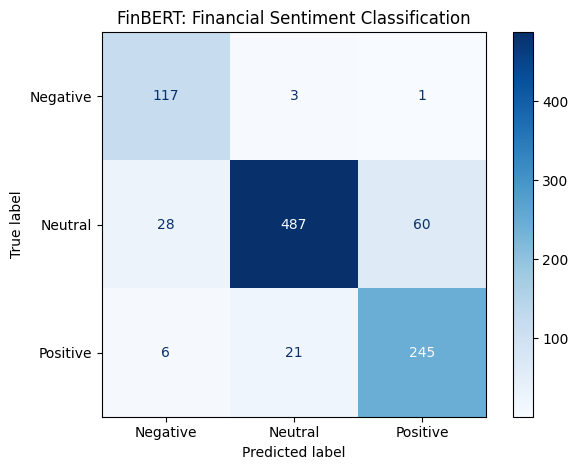

FinBERT evaluation completed.


In [14]:

# CELL 10: Evaluate FinBERT

from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import torch

finbert_predictions = []
finbert_probabilities = []

# Convert test sentences into a list
test_sentences = X_test_text.tolist()

# Read the model's label mapping
id2label = {
    int(k): str(v).lower()
    for k, v in finbert_model.config.id2label.items()
}

# Predict in batches to reduce memory usage
batch_size = 16

finbert_model.eval()

for start in range(0, len(test_sentences), batch_size):
    batch = test_sentences[start:start + batch_size]

    inputs = finbert_tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = finbert_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)

    batch_probabilities = probabilities.cpu().numpy()
    predicted_ids = np.argmax(batch_probabilities, axis=1)

    finbert_predictions.extend(
        id2label[int(idx)] for idx in predicted_ids
    )
    finbert_probabilities.extend(batch_probabilities.tolist())

# Normalize labels for comparison
y_test_clean = y_test.astype(str).str.lower().tolist()

print("FinBERT Accuracy:", round(accuracy_score(y_test_clean, finbert_predictions), 4))
print("FinBERT Macro F1:", round(f1_score(
    y_test_clean, finbert_predictions,
    labels=["negative", "neutral", "positive"],
    average="macro",
    zero_division=0
), 4))

print("\nClassification Report:\n")
print(classification_report(
    y_test_clean,
    finbert_predictions,
    labels=["negative", "neutral", "positive"],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(
    y_test_clean,
    finbert_predictions,
    labels=["negative", "neutral", "positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("FinBERT: Financial Sentiment Classification")
plt.tight_layout()
plt.show()

print("FinBERT evaluation completed.")


,Model,Accuracy,Macro F1
0,TF-IDF + Logistic Regression,72.21%,67.58%
1,FinBERT,87.71%,86.83%


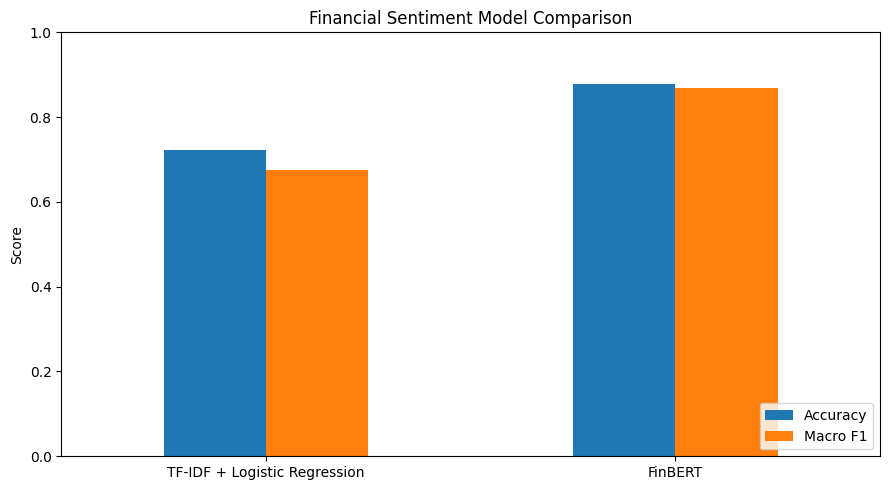

Recommended sentiment model: FinBERT
Accuracy improvement: 15.5 percentage points


In [15]:

# CELL 11: Compare TF-IDF Baseline vs FinBERT

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

# Calculate metrics on the same held-out test set
baseline_preds = improved_model.predict(X_test_text)

comparison = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "FinBERT"],
    "Accuracy": [
        accuracy_score(y_test, baseline_preds),
        accuracy_score(y_test_clean, finbert_predictions)
    ],
    "Macro F1": [
        f1_score(y_test, baseline_preds, average="macro"),
        f1_score(
            y_test_clean,
            finbert_predictions,
            labels=["negative", "neutral", "positive"],
            average="macro"
        )
    ]
})

display(
    comparison.style.format({
        "Accuracy": "{:.2%}",
        "Macro F1": "{:.2%}"
    })
)

# Plot comparison
comparison.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Financial Sentiment Model Comparison")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Recommended sentiment model: FinBERT")
print("Accuracy improvement:", round(
    (accuracy_score(y_test_clean, finbert_predictions)
     - accuracy_score(y_test, baseline_preds)) * 100, 2
), "percentage points")


In [16]:

# CELL 12: FinSight AI Sentiment Prediction

def predict_financial_sentiment(text):
    """
    Predict financial sentiment using pretrained FinBERT.
    Returns sentiment and class probabilities.
    """

    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty financial statement.")

    inputs = finbert_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    finbert_model.eval()

    with torch.no_grad():
        outputs = finbert_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)[0].cpu().numpy()

    id2label = {
        int(k): str(v).lower()
        for k, v in finbert_model.config.id2label.items()
    }

    scores = {
        id2label[i]: float(probabilities[i])
        for i in range(len(probabilities))
    }

    predicted_sentiment = max(scores, key=scores.get)

    return {
        "text": text,
        "sentiment": predicted_sentiment,
        "confidence": round(scores[predicted_sentiment] * 100, 2),
        "probabilities": {
            label: round(score * 100, 2)
            for label, score in scores.items()
        }
    }


# Test the function with sample financial statements

test_statements = [
    "The company reported strong revenue growth and improved profitability.",
    "The company suffered significant losses and declining sales.",
    "The company announced its annual general meeting for next month."
]

for statement in test_statements:
    result = predict_financial_sentiment(statement)

    print("\nStatement:", result["text"])
    print("Predicted sentiment:", result["sentiment"].upper())
    print("Confidence:", str(result["confidence"]) + "%")
    print("Class probabilities:", result["probabilities"])
    print("-" * 60)



Statement: The company reported strong revenue growth and improved profitability.
Predicted sentiment: POSITIVE
Confidence: 95.91%
Class probabilities: {'positive': 95.91, 'negative': 1.76, 'neutral': 2.33}
------------------------------------------------------------

Statement: The company suffered significant losses and declining sales.
Predicted sentiment: NEGATIVE
Confidence: 97.22%
Class probabilities: {'positive': 0.75, 'negative': 97.22, 'neutral': 2.03}
------------------------------------------------------------

Statement: The company announced its annual general meeting for next month.
Predicted sentiment: NEUTRAL
Confidence: 91.67%
Class probabilities: {'positive': 2.97, 'negative': 5.36, 'neutral': 91.67}
------------------------------------------------------------


In [17]:

# CELL 13: Financial Document Processing Setup

from pathlib import Path
import fitz
import re
import pandas as pd

# Create folders for documents and processed data
BASE_DIR = Path("/content/finsight_ai")
PDF_DIR = BASE_DIR / "documents"
OUTPUT_DIR = BASE_DIR / "processed"

PDF_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("FinSight AI document pipeline initialized.")
print("PDF folder:", PDF_DIR)
print("Processed data folder:", OUTPUT_DIR)


def extract_pdf_pages(pdf_path):
    """
    Extract text from a PDF while preserving page numbers.
    """
    pdf_path = Path(pdf_path)

    if not pdf_path.exists():
        raise FileNotFoundError(f"PDF not found: {pdf_path}")

    if pdf_path.suffix.lower() != ".pdf":
        raise ValueError("Please provide a PDF file.")

    pages = []

    with fitz.open(pdf_path) as document:
        for page_number, page in enumerate(document, start=1):
            text = page.get_text("text")
            text = re.sub(r"\s+", " ", text).strip()

            if text:
                pages.append({
                    "document": pdf_path.name,
                    "page": page_number,
                    "text": text
                })

    return pd.DataFrame(pages, columns=["document", "page", "text"])


print("\nReady to process financial annual reports.")
print("Upload a PDF into the documents folder to begin.")


FinSight AI document pipeline initialized.
PDF folder: /content/finsight_ai/documents
Processed data folder: /content/finsight_ai/processed

Ready to process financial annual reports.
Upload a PDF into the documents folder to begin.


In [19]:

# CELL 14: Download a public annual report automatically

import requests
from pathlib import Path

pdf_url = "https://www.ril.com/ar2024-25/pdf/RIL-IAR-2025.pdf"
pdf_path = PDF_DIR / "Reliance_Annual_Report_2024_25.pdf"

response = requests.get(pdf_url, timeout=120)
response.raise_for_status()

# Verify that the downloaded content is a PDF
if not response.content.startswith(b"%PDF"):
    raise ValueError("The downloaded file is not a valid PDF.")

pdf_path.write_bytes(response.content)

print("Annual report downloaded successfully!")
print("Company: Reliance Industries Limited")
print("Financial year: 2024-25")
print("File:", pdf_path.name)
print(f"File size: {pdf_path.stat().st_size / (1024 * 1024):.2f} MB")


Annual report downloaded successfully!
Company: Reliance Industries Limited
Financial year: 2024-25
File: Reliance_Annual_Report_2024_25.pdf
File size: 11.23 MB


In [20]:

# CELL 15: Extract and inspect the annual report

# Find downloaded PDFs in the documents folder
pdf_paths = list(PDF_DIR.glob("*.pdf"))

if not pdf_paths:
    raise FileNotFoundError(
        "No PDF found. Run Cell 14 first to download the annual report."
    )

# Extract text page by page
all_pages = []

for pdf_path in pdf_paths:
    extracted_pages = extract_pdf_pages(pdf_path)
    all_pages.append(extracted_pages)
    print(f"\nDocument: {pdf_path.name}")
    print(f"Pages with extracted text: {len(extracted_pages)}")

# Combine all extracted pages
documents_df = pd.concat(all_pages, ignore_index=True)

# Save extracted text for reuse
output_csv = OUTPUT_DIR / "annual_report_pages.csv"
documents_df.to_csv(output_csv, index=False)

print("\nExtraction completed.")
print("Total text-bearing pages:", len(documents_df))
print("Saved to:", output_csv)

# Preview the first extracted page
if not documents_df.empty:
    print("\n--- SAMPLE EXTRACTED TEXT ---")
    print("Document:", documents_df.iloc[0]["document"])
    print("Page:", documents_df.iloc[0]["page"])
    print(documents_df.iloc[0]["text"][:1500])
else:
    print("No selectable text found. This PDF may require OCR.")



Document: Reliance_Annual_Report_2024_25.pdf
Pages with extracted text: 147

Extraction completed.
Total text-bearing pages: 147
Saved to: /content/finsight_ai/processed/annual_report_pages.csv

--- SAMPLE EXTRACTED TEXT ---
Document: Reliance_Annual_Report_2024_25.pdf
Page: 1
Integrated Annual Report 2024-25 Realising Aspirations Accessibility Reliability Variety Mobility Connectivity Responsibility Sustainability


In [21]:

# CELL 16: Chunk financial documents for RAG

import pandas as pd
import re

def split_into_chunks(text, chunk_size=1000, overlap=200):
    """
    Split text into character-based chunks with overlapping context.
    """
    if not isinstance(text, str) or not text.strip():
        return []

    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunk = text[start:end].strip()

        if chunk:
            chunks.append(chunk)

        if end == len(text):
            break

        start = end - overlap

    return chunks


chunk_records = []

for _, row in documents_df.iterrows():
    page_chunks = split_into_chunks(row["text"])

    for chunk_number, chunk_text in enumerate(page_chunks, start=1):
        chunk_records.append({
            "document": row["document"],
            "page": int(row["page"]),
            "chunk_id": f'{row["document"]}_p{row["page"]}_c{chunk_number}',
            "text": chunk_text
        })

chunks_df = pd.DataFrame(chunk_records)

if chunks_df.empty:
    raise ValueError("No chunks were created. Check the extracted PDF text.")

chunks_path = OUTPUT_DIR / "annual_report_chunks.csv"
chunks_df.to_csv(chunks_path, index=False)

print("Chunking completed successfully!")
print("Total chunks:", len(chunks_df))
print("Average characters per chunk:", round(chunks_df["text"].str.len().mean()))
print("Saved to:", chunks_path)

print("\n--- SAMPLE CHUNK ---")
print("Document:", chunks_df.iloc[0]["document"])
print("Page:", chunks_df.iloc[0]["page"])
print("Chunk ID:", chunks_df.iloc[0]["chunk_id"])
print(chunks_df.iloc[0]["text"][:700])


Chunking completed successfully!
Total chunks: 1206
Average characters per chunk: 948
Saved to: /content/finsight_ai/processed/annual_report_chunks.csv

--- SAMPLE CHUNK ---
Document: Reliance_Annual_Report_2024_25.pdf
Page: 1
Chunk ID: Reliance_Annual_Report_2024_25.pdf_p1_c1
Integrated Annual Report 2024-25 Realising Aspirations Accessibility Reliability Variety Mobility Connectivity Responsibility Sustainability


In [22]:

# CELL 17: Create semantic embeddings for report chunks

from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd

if "chunks_df" not in globals() or chunks_df.empty:
    raise ValueError("Run Cell 16 first to create document chunks.")

# Load the embedding model
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Convert chunks into embeddings
chunk_texts = chunks_df["text"].astype(str).tolist()

embeddings = embedding_model.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

# Check the resulting index data
print("Semantic embeddings created successfully!")
print("Number of chunks:", len(chunk_texts))
print("Embedding matrix shape:", embeddings.shape)
print("Embedding dimensions:", embeddings.shape[1])

# Save embeddings for later reuse
embeddings_path = OUTPUT_DIR / "annual_report_embeddings.npy"
np.save(embeddings_path, embeddings)

print("Embeddings saved to:", embeddings_path)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/38 [00:00<?, ?it/s]

Semantic embeddings created successfully!
Number of chunks: 1206
Embedding matrix shape: (1206, 384)
Embedding dimensions: 384
Embeddings saved to: /content/finsight_ai/processed/annual_report_embeddings.npy


In [23]:

# CELL 18: Semantic Retrieval Engine

import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_financial_context(question, top_k=5):
    """
    Retrieve the most relevant report chunks for a question.
    Returns passages with source document, page, and relevance score.
    """

    if not isinstance(question, str) or not question.strip():
        raise ValueError("Please enter a question.")

    if "chunks_df" not in globals() or chunks_df.empty:
        raise ValueError("Run Cell 16 first.")

    if "embeddings" not in globals():
        raise ValueError("Run Cell 17 first.")

    if len(chunks_df) != len(embeddings):
        raise ValueError("Chunk and embedding counts do not match.")

    # Embed the question using the same model as the document chunks
    question_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    # Compare question with every chunk
    similarity_scores = cosine_similarity(
        question_embedding,
        embeddings
    )[0]

    # Get the highest-scoring chunks
    top_indices = np.argsort(similarity_scores)[::-1][:min(top_k, len(chunks_df))]

    results = chunks_df.iloc[top_indices].copy()
    results["similarity"] = similarity_scores[top_indices]

    return results.reset_index(drop=True)


# Test the retrieval engine
sample_question = "What does the annual report say about revenue and financial performance?"

search_results = retrieve_financial_context(sample_question, top_k=5)

print("Question:", sample_question)
print("\nRetrieved passages:\n")

for rank, row in search_results.iterrows():
    print(f"Result {rank + 1} | Similarity: {row['similarity']:.3f}")
    print(f"Source: {row['document']} | Page: {row['page']}")
    print(row["text"][:700])
    print("-" * 80)


Question: What does the annual report say about revenue and financial performance?

Retrieved passages:

Result 1 | Similarity: 0.617
Source: Reliance_Annual_Report_2024_25.pdf | Page: 40
Board’s Report Dear Members, The Board of Directors present the Company’s Forty-eighth Annual Report (Post-IPO) and the Company’s audited financial statements for the financial year ended March 31, 2025. Financial Results The Company’s financial performance (standalone and consolidated) for the year ended March 31, 2025 is summarised below: Standalone Consolidated 2024-25 2023-24 2024-25 2023-24 K crore US$ million* K crore US$ million* K crore US$ million* K crore US$ million* Profit Before Tax 46,128 5,397 55,273 6,627 1,06,017 12,403 1,04,340 12,509 Current Tax (9,399) (1,100) (10,922) (1,310) (12,758) (1,493) (13,590) (1,629) Deferred Tax (1,467) (172) (2,309) (277) (12,472) (1,459) (12,
--------------------------------------------------------------------------------
Result 2 | Similarity: 0.531
S

In [24]:

# CELL 19: RAG Question Answering with Source Citations

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

RAG_MODEL_NAME = "google/flan-t5-base"

try:
    rag_tokenizer = AutoTokenizer.from_pretrained(RAG_MODEL_NAME)
    rag_model = AutoModelForSeq2SeqLM.from_pretrained(RAG_MODEL_NAME)
    rag_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    rag_model.to(rag_device)
    rag_model.eval()
    rag_available = True
    print("RAG answer-generation model loaded successfully.")
    print("Device:", rag_device)

except Exception as error:
    rag_available = False
    print("Answer-generation model could not be loaded.")
    print("Retrieval and source excerpts will still be available.")
    print("Reason:", str(error)[:300])


def ask_finsight(question, top_k=4):
    """
    Answer a financial question using retrieved report passages.
    Include document and page citations.
    """

    retrieved = retrieve_financial_context(question, top_k=top_k)

    if retrieved.empty:
        return {
            "question": question,
            "answer": "No relevant report passages were found.",
            "sources": []
        }

    context_parts = []
    sources = []

    for _, row in retrieved.iterrows():
        context_parts.append(
            f"[Source: {row['document']}, Page {row['page']}]\n{row['text']}"
        )

        sources.append({
            "document": row["document"],
            "page": int(row["page"]),
            "similarity": round(float(row["similarity"]), 3),
            "text": row["text"]
        })

    context = "\n\n".join(context_parts)

    if rag_available:
        prompt = (
            "Answer the question using only the financial report context. "
            "If the context does not contain enough evidence, say so. "
            "Do not invent figures. Mention source page numbers when possible.\n\n"
            f"Context:\n{context[:4500]}\n\n"
            f"Question: {question}\n"
            "Answer:"
        )

        try:
            inputs = rag_tokenizer(
                prompt,
                return_tensors="pt",
                truncation=True,
                max_length=1024
            ).to(rag_device)

            with torch.no_grad():
                output = rag_model.generate(
                    **inputs,
                    max_new_tokens=180,
                    num_beams=4,
                    early_stopping=True
                )

            answer = rag_tokenizer.decode(
                output[0],
                skip_special_tokens=True
            )

        except Exception as error:
            answer = (
                "Answer generation failed, so use the retrieved source excerpts "
                "below to verify the information. "
                f"Technical detail: {str(error)[:200]}"
            )
    else:
        answer = (
            "The answer generator is unavailable. Review the retrieved "
            "financial report excerpts listed in the sources."
        )

    return {
        "question": question,
        "answer": answer,
        "sources": sources
    }


# Test the RAG system
result = ask_finsight(
    "What does the report say about the company's revenue and financial performance?"
)

print("QUESTION:")
print(result["question"])

print("\nANSWER:")
print(result["answer"])

print("\nSOURCES:")
for source in result["sources"]:
    print(
        f"- {source['document']}, page {source['page']} "
        f"(similarity: {source['similarity']})"
    )
    print(source["text"][:350])
    print()


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

RAG answer-generation model loaded successfully.
Device: cpu
QUESTION:
What does the report say about the company's revenue and financial performance?

ANSWER:
Reliance Industries Limited Integrated Annual Report 2024-25 To The Members of Reliance Industries Limited Report on the Audit of the Consolidated Financial Statements Opinion

SOURCES:
- Reliance_Annual_Report_2024_25.pdf, page 40 (similarity: 0.674)
Board’s Report Dear Members, The Board of Directors present the Company’s Forty-eighth Annual Report (Post-IPO) and the Company’s audited financial statements for the financial year ended March 31, 2025. Financial Results The Company’s financial performance (standalone and consolidated) for the year ended March 31, 2025 is summarised below: Standal

- Reliance_Annual_Report_2024_25.pdf, page 40 (similarity: 0.57)
Disney”), by the transfer of the media and JioCinema businesses into Star India Private Limited. The JV is now a subsidiary of the Company and owned 16.34% by the Company,

In [25]:

# CELL 20: Interactive FinSight AI Q&A

import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

question_box = widgets.Textarea(
    value="What does the report say about revenue and financial performance?",
    placeholder="Ask a question about the annual report...",
    description="Question:",
    layout=widgets.Layout(width="100%", height="90px")
)

ask_button = widgets.Button(
    description="Ask FinSight AI",
    button_style="primary",
    icon="search"
)

answer_output = widgets.Output()

def handle_question(_):
    with answer_output:
        clear_output(wait=True)

        question = question_box.value.strip()

        if not question:
            display(Markdown("Please enter a question first."))
            return

        display(Markdown("### Searching the annual report..."))

        try:
            result = ask_finsight(question, top_k=4)

            clear_output(wait=True)

            display(Markdown("## FinSight AI Answer"))
            display(Markdown(f"**Question:** {result['question']}"))
            display(Markdown(result["answer"]))

            display(Markdown("### Sources"))
            for source in result["sources"]:
                display(Markdown(
                    f"**{source['document']} | Page {source['page']}** "
                    f"(similarity: {source['similarity']})\n\n"
                    f"> {source['text'][:600]}"
                ))

        except Exception as error:
            clear_output(wait=True)
            display(Markdown(f"**Error:** `{str(error)}`"))

ask_button.on_click(handle_question)

display(question_box, ask_button, answer_output)


Textarea(value='What does the report say about revenue and financial performance?', description='Question:', l…

Button(button_style='primary', description='Ask FinSight AI', icon='search', style=ButtonStyle())

Output()

In [26]:

# CELL 21: Financial Ratio Analysis

import pandas as pd
import numpy as np

def calculate_financial_ratios(
    current_assets,
    current_liabilities,
    total_debt,
    total_equity,
    revenue,
    net_profit,
    total_assets
):
    """
    Calculate key financial ratios.
    All monetary inputs must use the same units.
    """

    inputs = {
        "Current Assets": current_assets,
        "Current Liabilities": current_liabilities,
        "Total Debt": total_debt,
        "Total Equity": total_equity,
        "Revenue": revenue,
        "Net Profit": net_profit,
        "Total Assets": total_assets
    }

    for name, value in inputs.items():
        if not np.isfinite(value) or value < 0:
            raise ValueError(f"{name} must be a finite, non-negative number.")

    if current_liabilities == 0:
        current_ratio = np.nan
    else:
        current_ratio = current_assets / current_liabilities

    if total_equity == 0:
        debt_to_equity = np.nan
    else:
        debt_to_equity = total_debt / total_equity

    if revenue == 0:
        net_profit_margin = np.nan
    else:
        net_profit_margin = (net_profit / revenue) * 100

    if total_assets == 0:
        return_on_assets = np.nan
    else:
        return_on_assets = (net_profit / total_assets) * 100

    return pd.DataFrame({
        "Financial Ratio": [
            "Current Ratio",
            "Debt-to-Equity Ratio",
            "Net Profit Margin (%)",
            "Return on Assets (%)"
        ],
        "Value": [
            current_ratio,
            debt_to_equity,
            net_profit_margin,
            return_on_assets
        ]
    })


# DEMONSTRATION ONLY: fictional values, not Reliance's actual results
sample_ratios = calculate_financial_ratios(
    current_assets=5000,
    current_liabilities=2500,
    total_debt=3000,
    total_equity=6000,
    revenue=10000,
    net_profit=1200,
    total_assets=12000
)

print("DEMONSTRATION ONLY: these are fictional figures.")
display(sample_ratios.round(2))


DEMONSTRATION ONLY: these are fictional figures.


,Financial Ratio,Value
0,Current Ratio,2.0
1,Debt-to-Equity Ratio,0.5
2,Net Profit Margin (%),12.0
3,Return on Assets (%),10.0


In [27]:

# CELL 22: Search annual report for financial figures

import re
import pandas as pd

# Search terms commonly found in financial statements
financial_terms = [
    "revenue from operations",
    "total income",
    "profit after tax",
    "profit for the year",
    "total assets",
    "total liabilities",
    "current assets",
    "current liabilities",
    "borrowings",
    "total equity",
    "cash flow from operating activities"
]

if "documents_df" not in globals() or documents_df.empty:
    raise ValueError("Run Cell 15 first to extract the annual report.")

matches = []

for _, row in documents_df.iterrows():
    text = str(row["text"])
    text_lower = text.lower()

    found_terms = [
        term for term in financial_terms
        if term in text_lower
    ]

    if found_terms:
        matches.append({
            "document": row["document"],
            "page": int(row["page"]),
            "matched_terms": ", ".join(found_terms),
            "text_excerpt": text[:1200]
        })

financial_pages_df = pd.DataFrame(matches)

if financial_pages_df.empty:
    print("No matching financial terms found.")
    print("The report may use different terminology or require OCR.")
else:
    print("Pages containing financial statement terms:", len(financial_pages_df))
    display(
        financial_pages_df[
            ["document", "page", "matched_terms"]
        ].head(30)
    )

    print("\n--- FIRST MATCHING EXCERPT ---")
    first_match = financial_pages_df.iloc[0]
    print("Document:", first_match["document"])
    print("Page:", first_match["page"])
    print(first_match["text_excerpt"])

    # Save results for review
    matches_path = OUTPUT_DIR / "financial_statement_pages.csv"
    financial_pages_df.to_csv(matches_path, index=False)
    print("\nSaved search results to:", matches_path)


Pages containing financial statement terms: 62


,document,page,matched_terms
0,Reliance_Annual_Report_2024_25.pdf,2,total equity
1,Reliance_Annual_Report_2024_25.pdf,5,"total income, profit after tax, profit for the..."
2,Reliance_Annual_Report_2024_25.pdf,7,revenue from operations
3,Reliance_Annual_Report_2024_25.pdf,8,revenue from operations
4,Reliance_Annual_Report_2024_25.pdf,10,revenue from operations
5,Reliance_Annual_Report_2024_25.pdf,15,borrowings
6,Reliance_Annual_Report_2024_25.pdf,34,borrowings
7,Reliance_Annual_Report_2024_25.pdf,35,borrowings
8,Reliance_Annual_Report_2024_25.pdf,36,borrowings
9,Reliance_Annual_Report_2024_25.pdf,37,borrowings



--- FIRST MATCHING EXCERPT ---
Document: Reliance_Annual_Report_2024_25.pdf
Page: 2
TABLE OF CONTENTS REPORTING SUITE 2024-25 RIL’s Annual Reporting suite brings together the financial, non-financial, risk, and sustainability performance for the year. Corporate Overview 2 Reliance at a Glance 3 Stakeholder Value Creation 4 Chairman and Managing Director’s Statement 6 10-year Financial Highlights Management Discussion and Analysis 7 Financial Performance and Review Business Overview 9 Retail 12 Digital Services 15 Media and Entertainment 19 Oil to Chemicals 22 Oil and Gas 25 Risk and Governance 28 Major Awards and Recognitions Integrated Approach to Sustainable Growth 30 Integrated Approach to ESG Governance 32 Making Significant Strides towards a Net Carbon Zero Future 33 Approach to Climate-related Disclosures 34 N Natural Capital 37 H Human Capital 38 M Manufactured Capital 39 I Intellectual Capital 39 S Social and Relationship Capital 41 Independent Assurance on Sustainability Dis

In [28]:

# CELL 23: Source-Tracked Financial Data

import pandas as pd
from IPython.display import display

# Create an empty table for verified financial figures.
# We will populate it only after inspecting the actual report pages.

financial_data_columns = [
    "company",
    "financial_year",
    "statement_type",
    "metric",
    "value",
    "unit",
    "document",
    "page",
    "verification_status"
]

financial_data = pd.DataFrame(columns=financial_data_columns)

# Show the pages found in Cell 22 for manual verification
if "financial_pages_df" not in globals() or financial_pages_df.empty:
    print("No financial statement pages are available.")
    print("Run Cell 22 first.")
else:
    print("Financial statement pages available for inspection:")
    display(
        financial_pages_df[
            ["document", "page", "matched_terms", "text_excerpt"]
        ].head(10)
    )

print("\nFinancial data table initialized.")
display(financial_data)

# Save the empty schema for future verified entries
financial_data_path = OUTPUT_DIR / "verified_financial_data.csv"
financial_data.to_csv(financial_data_path, index=False)

print("Template saved to:", financial_data_path)
print("No company figures have been assumed or fabricated.")


Financial statement pages available for inspection:


,document,page,matched_terms,text_excerpt
0,Reliance_Annual_Report_2024_25.pdf,2,total equity,TABLE OF CONTENTS REPORTING SUITE 2024-25 RIL’...
1,Reliance_Annual_Report_2024_25.pdf,5,"total income, profit after tax, profit for the...",Operating Environment Global economic growth r...
2,Reliance_Annual_Report_2024_25.pdf,7,revenue from operations,Outlook India’s retail sector has been one of ...
3,Reliance_Annual_Report_2024_25.pdf,8,revenue from operations,Jio has led every communication technology tra...
4,Reliance_Annual_Report_2024_25.pdf,10,revenue from operations,Outlook Backed by a diverse content slate acro...
5,Reliance_Annual_Report_2024_25.pdf,15,borrowings,stakeholders and remains firmly committed to m...
6,Reliance_Annual_Report_2024_25.pdf,34,borrowings,CEO / CFO CERTIFICATE Under Regulation 17(8) o...
7,Reliance_Annual_Report_2024_25.pdf,35,borrowings,"of Executive, Non-Executive and Independent Di..."
8,Reliance_Annual_Report_2024_25.pdf,36,borrowings,(e) The Securities and Exchange Board of Indi...
9,Reliance_Annual_Report_2024_25.pdf,37,borrowings,"During the period under audit, the Company has..."



Financial data table initialized.


,company,financial_year,statement_type,metric,value,unit,document,page,verification_status


Template saved to: /content/finsight_ai/processed/verified_financial_data.csv
No company figures have been assumed or fabricated.


In [29]:

# CELL 24: Inspect Financial Statement Evidence

import re
import pandas as pd
from IPython.display import display

if "documents_df" not in globals() or documents_df.empty:
    raise ValueError("Run Cell 15 first.")

# Search for important financial statement headings and metrics
priority_terms = [
    "revenue from operations",
    "profit after tax",
    "profit for the year",
    "total assets",
    "total liabilities",
    "total equity",
    "current assets",
    "current liabilities",
    "borrowings"
]

evidence_rows = []

for _, row in documents_df.iterrows():
    text = str(row["text"])
    text_lower = text.lower()

    matched = [term for term in priority_terms if term in text_lower]

    if matched:
        evidence_rows.append({
            "document": row["document"],
            "page": int(row["page"]),
            "matched_terms": ", ".join(matched),
            "text": text
        })

evidence_df = pd.DataFrame(evidence_rows)

if evidence_df.empty:
    print("No matching financial terms found.")
else:
    # Prioritize pages containing revenue, profit, assets, or liabilities
    priority_order = [
        "revenue from operations",
        "profit after tax",
        "profit for the year",
        "total assets",
        "total liabilities"
    ]

    evidence_df["priority"] = evidence_df["matched_terms"].apply(
        lambda terms: min(
            [priority_order.index(term) for term in priority_order
             if term in terms.split(", ")] or [len(priority_order)]
        )
    )

    evidence_df = evidence_df.sort_values(
        ["priority", "page"]
    ).reset_index(drop=True)

    print("Relevant pages found:", len(evidence_df))

    for _, row in evidence_df.head(12).iterrows():
        print("\n" + "=" * 80)
        print(f"Document: {row['document']} | PDF page: {row['page']}")
        print("Terms:", row["matched_terms"])
        print(row["text"][:1800])

    # Save evidence for review
    evidence_path = OUTPUT_DIR / "financial_statement_evidence.csv"
    evidence_df.drop(columns=["priority"]).to_csv(
        evidence_path, index=False
    )
    print("\nEvidence saved to:", evidence_path)


Relevant pages found: 62

Document: Reliance_Annual_Report_2024_25.pdf | PDF page: 7
Terms: revenue from operations
Outlook India’s retail sector has been one of the fastest growing consumer markets in the world. Government initiatives, including tax relief and supportive economic policies are expected to boost disposable incomes and stimulate consumption. With strong rural demand and projected GDP growth, the retail sector is poised for sustained growth. Overall, the outlook is positive for India’s retail industry, characterised by technological progress, market expansion, greater consumer engagement, and launch of innovative products. SCOT Analysis S C CHALLENGES • Upward pressure on rentals due to demand-supply mismatch for high quality real estate • Availability of trained manpower to support rapid expansion O OPPORTUNITIES • Rising consumer aspirations and growing disposable incomes present significant growth potential • Accelerating the growth of own brands and exclusive brand pa

In [30]:

# CELL 25: Extract candidate financial values for review

import re
import pandas as pd

if "evidence_df" not in globals() or evidence_df.empty:
    raise ValueError("Run Cell 24 first to identify relevant pages.")

metric_patterns = {
    "revenue": r"revenue from operations",
    "profit_after_tax": r"profit after tax|profit for the year",
    "total_assets": r"total assets",
    "total_liabilities": r"total liabilities",
    "current_assets": r"current assets",
    "current_liabilities": r"current liabilities",
    "borrowings": r"borrowings",
    "total_equity": r"total equity|total shareholders['’]? equity"
}

# Capture numbers that appear after a matching metric.
# The nearby text is retained because automated matching can be ambiguous.
candidate_rows = []

number_pattern = re.compile(
    r"[-+]?\d[\d,]*(?:\.\d+)?"
)

for _, row in evidence_df.iterrows():
    text = str(row["text"])

    for metric, pattern in metric_patterns.items():
        for match in re.finditer(pattern, text, flags=re.IGNORECASE):
            start = match.start()
            end = min(len(text), match.end() + 220)
            excerpt = text[start:end]

            numbers = number_pattern.findall(
                excerpt[match.end() - start:]
            )

            candidate_rows.append({
                "document": row["document"],
                "page": int(row["page"]),
                "metric_candidate": metric,
                "matched_label": match.group(0),
                "nearby_numbers": ", ".join(numbers[:8]),
                "context_for_manual_verification": excerpt
            })

candidates_df = pd.DataFrame(candidate_rows)

if candidates_df.empty:
    print("No candidate values found. Inspect the financial pages manually.")
else:
    print("Candidate metric matches:", len(candidates_df))
    display(candidates_df.head(25))

    candidate_path = OUTPUT_DIR / "financial_value_candidates.csv"
    candidates_df.to_csv(candidate_path, index=False)
    print("\nCandidates saved to:", candidate_path)

print(
    "\nIMPORTANT: These are unverified candidates. "
    "Do not use them in financial ratios until the value, year, "
    "statement type, and unit have been checked against the source."
)


Candidate metric matches: 239


,document,page,metric_candidate,matched_label,nearby_numbers,context_for_manual_verification
0,Reliance_Annual_Report_2024_25.pdf,7,revenue,Revenue from operations,"2,91,043, 2,73,131, 6.6, 25,094, 23,108, 8.6, ...","Revenue from operations 2,91,043 2,73,131 6.6%..."
1,Reliance_Annual_Report_2024_25.pdf,7,revenue,Revenue from operations,"10, 11, 2024, -25",Revenue from operations 10 11 Reliance Industr...
2,Reliance_Annual_Report_2024_25.pdf,8,revenue,Revenue from operations,"1,31,336, 1,13,176, 16.0, 65,001, 56,675, 14.7...","Revenue from operations 1,31,336 1,13,176 16.0..."
3,Reliance_Annual_Report_2024_25.pdf,8,revenue,Revenue from Operations,"2024, -25, 15.9, 14.7",Revenue from Operations Revenue and EBITDA gro...
4,Reliance_Annual_Report_2024_25.pdf,10,revenue,Revenue from operations,"17,762, 10,157, 74.9, 1,833, 765, 139.6, 10.3,...","Revenue from operations 17,762 10,157 74.9% EB..."
5,Reliance_Annual_Report_2024_25.pdf,10,revenue,Revenue from operations,"9, 10",Revenue from operations TV Entertainment JioSt...
6,Reliance_Annual_Report_2024_25.pdf,58,revenue,Revenue from Operations,"25, 5,32,792, 5,47,942, 26, 16,094, 12,128, 5,...","Revenue from Operations 25 5,32,792 5,47,942 O..."
7,Reliance_Annual_Report_2024_25.pdf,58,profit_after_tax,Profit for the Year,"35,262, 42,042, 26.1, 255, 38, 26.1, 29, 11","Profit for the Year 35,262 42,042 Other Compre..."
8,Reliance_Annual_Report_2024_25.pdf,74,revenue,revenue from operations,"31, 2025, 31, 2024, 24",revenue from operations against the contract l...
9,Reliance_Annual_Report_2024_25.pdf,74,revenue,Revenue from Operations,"4,91,622, 4,87,451, 24,783, 24,425, 10, 17, 1,...",Revenue from Operations Disaggregated Revenue ...



Candidates saved to: /content/finsight_ai/processed/financial_value_candidates.csv

IMPORTANT: These are unverified candidates. Do not use them in financial ratios until the value, year, statement type, and unit have been checked against the source.


In [31]:

# CELL 26: Validate Financial Figures

import pandas as pd
import numpy as np

if "candidates_df" not in globals() or candidates_df.empty:
    raise ValueError("Run Cell 25 first to generate candidate values.")

# Create a review table from the extracted candidates
review_df = candidates_df[
    [
        "document",
        "page",
        "metric_candidate",
        "matched_label",
        "nearby_numbers",
        "context_for_manual_verification"
    ]
].copy()

review_df["verified_value"] = np.nan
review_df["financial_year"] = ""
review_df["statement_type"] = ""
review_df["unit"] = ""
review_df["verified_by_source_review"] = False

print("Review these candidates against the original PDF.")
print("Check the reporting year, consolidated/standalone statement, and unit.")
display(review_df.head(20))

# Save the review worksheet
review_path = OUTPUT_DIR / "financial_value_review.csv"
review_df.to_csv(review_path, index=False)

print("\nReview worksheet saved to:", review_path)
print("No extracted figure has been marked as verified.")


Review these candidates against the original PDF.
Check the reporting year, consolidated/standalone statement, and unit.


,document,page,metric_candidate,matched_label,nearby_numbers,context_for_manual_verification,verified_value,financial_year,statement_type,unit,verified_by_source_review
0,Reliance_Annual_Report_2024_25.pdf,7,revenue,Revenue from operations,"2,91,043, 2,73,131, 6.6, 25,094, 23,108, 8.6, ...","Revenue from operations 2,91,043 2,73,131 6.6%...",NaN,,,,False
1,Reliance_Annual_Report_2024_25.pdf,7,revenue,Revenue from operations,"10, 11, 2024, -25",Revenue from operations 10 11 Reliance Industr...,NaN,,,,False
2,Reliance_Annual_Report_2024_25.pdf,8,revenue,Revenue from operations,"1,31,336, 1,13,176, 16.0, 65,001, 56,675, 14.7...","Revenue from operations 1,31,336 1,13,176 16.0...",NaN,,,,False
3,Reliance_Annual_Report_2024_25.pdf,8,revenue,Revenue from Operations,"2024, -25, 15.9, 14.7",Revenue from Operations Revenue and EBITDA gro...,NaN,,,,False
4,Reliance_Annual_Report_2024_25.pdf,10,revenue,Revenue from operations,"17,762, 10,157, 74.9, 1,833, 765, 139.6, 10.3,...","Revenue from operations 17,762 10,157 74.9% EB...",NaN,,,,False
5,Reliance_Annual_Report_2024_25.pdf,10,revenue,Revenue from operations,"9, 10",Revenue from operations TV Entertainment JioSt...,NaN,,,,False
6,Reliance_Annual_Report_2024_25.pdf,58,revenue,Revenue from Operations,"25, 5,32,792, 5,47,942, 26, 16,094, 12,128, 5,...","Revenue from Operations 25 5,32,792 5,47,942 O...",NaN,,,,False
7,Reliance_Annual_Report_2024_25.pdf,58,profit_after_tax,Profit for the Year,"35,262, 42,042, 26.1, 255, 38, 26.1, 29, 11","Profit for the Year 35,262 42,042 Other Compre...",NaN,,,,False
8,Reliance_Annual_Report_2024_25.pdf,74,revenue,revenue from operations,"31, 2025, 31, 2024, 24",revenue from operations against the contract l...,NaN,,,,False
9,Reliance_Annual_Report_2024_25.pdf,74,revenue,Revenue from Operations,"4,91,622, 4,87,451, 24,783, 24,425, 10, 17, 1,...",Revenue from Operations Disaggregated Revenue ...,NaN,,,,False



Review worksheet saved to: /content/finsight_ai/processed/financial_value_review.csv
No extracted figure has been marked as verified.


In [32]:

# CELL 27: Financial Risk Assessment Engine

import pandas as pd
import numpy as np

def assess_financial_risk(
    current_assets,
    current_liabilities,
    total_debt,
    total_equity,
    revenue,
    net_profit
):
    """
    Calculate selected financial ratios and apply illustrative
    screening rules. Monetary values must use the same unit.
    """

    inputs = {
        "current_assets": current_assets,
        "current_liabilities": current_liabilities,
        "total_debt": total_debt,
        "total_equity": total_equity,
        "revenue": revenue,
        "net_profit": net_profit
    }

    for name, value in inputs.items():
        if not np.isfinite(value):
            raise ValueError(f"{name} must be a finite number.")

    if any(value < 0 for name, value in inputs.items()
           if name != "net_profit"):
        raise ValueError("Assets, liabilities, debt, equity, and revenue cannot be negative.")

    current_ratio = (
        current_assets / current_liabilities
        if current_liabilities > 0 else np.nan
    )

    debt_to_equity = (
        total_debt / total_equity
        if total_equity > 0 else np.nan
    )

    profit_margin = (
        (net_profit / revenue) * 100
        if revenue > 0 else np.nan
    )

    findings = []
    risk_points = 0
    evaluated_metrics = 0

    # Illustrative rules, not industry-specific conclusions
    if np.isfinite(current_ratio):
        evaluated_metrics += 1
        if current_ratio < 1:
            findings.append("Liquidity: current ratio below 1.0.")
            risk_points += 1
        else:
            findings.append("Liquidity: current ratio is at least 1.0.")
    else:
        findings.append("Liquidity: insufficient data to calculate current ratio.")

    if np.isfinite(debt_to_equity):
        evaluated_metrics += 1
        if debt_to_equity > 2:
            findings.append("Leverage: debt-to-equity exceeds 2.0.")
            risk_points += 1
        else:
            findings.append("Leverage: debt-to-equity is at most 2.0.")
    else:
        findings.append("Leverage: insufficient data to calculate debt-to-equity.")

    if np.isfinite(profit_margin):
        evaluated_metrics += 1
        if profit_margin < 0:
            findings.append("Profitability: net profit margin is negative.")
            risk_points += 1
        else:
            findings.append("Profitability: net profit margin is non-negative.")
    else:
        findings.append("Profitability: insufficient data to calculate profit margin.")

    if evaluated_metrics == 0:
        overall = "Insufficient data"
    elif risk_points >= 2:
        overall = "Higher screening risk"
    elif risk_points == 1:
        overall = "Some screening concerns"
    else:
        overall = "Fewer screening concerns"

    metrics = pd.DataFrame([
        {"Metric": "Current Ratio", "Value": current_ratio},
        {"Metric": "Debt-to-Equity Ratio", "Value": debt_to_equity},
        {"Metric": "Net Profit Margin (%)", "Value": profit_margin}
    ])

    return {
        "overall_screening_result": overall,
        "risk_points": risk_points,
        "metrics": metrics,
        "findings": findings
    }


# DEMONSTRATION ONLY: fictional values, not Reliance's financial results
demo_result = assess_financial_risk(
    current_assets=5000,
    current_liabilities=2500,
    total_debt=3000,
    total_equity=6000,
    revenue=10000,
    net_profit=1200
)

print("DEMONSTRATION ONLY: fictional financial inputs")
print("Screening result:", demo_result["overall_screening_result"])
print("Risk points:", demo_result["risk_points"])

display(demo_result["metrics"].round(2))

print("\nFindings:")
for finding in demo_result["findings"]:
    print("-", finding)


DEMONSTRATION ONLY: fictional financial inputs
Screening result: Fewer screening concerns
Risk points: 0


,Metric,Value
0,Current Ratio,2.0
1,Debt-to-Equity Ratio,0.5
2,Net Profit Margin (%),12.0



Findings:
- Liquidity: current ratio is at least 1.0.
- Leverage: debt-to-equity is at most 2.0.
- Profitability: net profit margin is non-negative.


In [33]:

# CELL 28: Run Risk Assessment from Verified Data

import pandas as pd
import numpy as np

REQUIRED_METRICS = [
    "current_assets",
    "current_liabilities",
    "total_debt",
    "total_equity",
    "revenue",
    "net_profit"
]

def run_risk_assessment_from_table(financial_data, financial_year, company):
    """
    Use only verified values from one company, year, and statement type.
    Expected metric names:
    current_assets, current_liabilities, total_debt,
    total_equity, revenue, net_profit
    """

    required_columns = {
        "company", "financial_year", "statement_type", "metric",
        "value", "unit", "document", "page", "verification_status"
    }

    missing_columns = required_columns - set(financial_data.columns)
    if missing_columns:
        raise ValueError(
            f"Financial data table is missing columns: {sorted(missing_columns)}"
        )

    selected = financial_data[
        (financial_data["company"].astype(str).str.lower() == company.lower()) &
        (financial_data["financial_year"].astype(str) == str(financial_year)) &
        (financial_data["verification_status"].astype(str).str.lower() == "verified")
    ].copy()

    if selected.empty:
        raise ValueError(
            "No verified figures found for this company and financial year. "
            "Review the report and populate financial_data first."
        )

    if selected["statement_type"].nunique() != 1:
        raise ValueError(
            "Use one statement type only, such as consolidated or standalone."
        )

    if selected["unit"].nunique() != 1:
        raise ValueError(
            "The figures use different units. Convert them to a common unit first."
        )

    selected["metric"] = selected["metric"].astype(str).str.lower()

    if selected["metric"].duplicated().any():
        raise ValueError(
            "Duplicate metric values found. Resolve duplicates before analysis."
        )

    values = dict(zip(selected["metric"], selected["value"]))

    missing_metrics = [metric for metric in REQUIRED_METRICS if metric not in values]
    if missing_metrics:
        raise ValueError(
            f"Missing required verified metrics: {missing_metrics}"
        )

    numeric_values = {}
    for metric in REQUIRED_METRICS:
        value = pd.to_numeric(values[metric], errors="coerce")
        if pd.isna(value) or not np.isfinite(value):
            raise ValueError(f"Invalid numeric value for {metric}.")
        numeric_values[metric] = float(value)

    result = assess_financial_risk(
        current_assets=numeric_values["current_assets"],
        current_liabilities=numeric_values["current_liabilities"],
        total_debt=numeric_values["total_debt"],
        total_equity=numeric_values["total_equity"],
        revenue=numeric_values["revenue"],
        net_profit=numeric_values["net_profit"]
    )

    print(f"Company: {company}")
    print(f"Financial year: {financial_year}")
    print(f"Statement type: {selected['statement_type'].iloc[0]}")
    print(f"Unit: {selected['unit'].iloc[0]}")
    print(f"Screening result: {result['overall_screening_result']}")

    display(result["metrics"].round(2))

    print("\nSource references:")
    display(selected[["metric", "value", "document", "page"]])

    print("\nFindings:")
    for finding in result["findings"]:
        print("-", finding)

    return result


print("Risk assessment connector initialized.")
print("It will run only when all required financial figures are verified.")


Risk assessment connector initialized.
It will run only when all required financial figures are verified.


In [34]:

# CELL 29: Financial Trend Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def analyze_financial_trends(
    financial_data,
    company,
    metric="revenue",
    statement_type="Consolidated"
):
    """
    Analyze a financial metric across multiple verified financial years.

    Required columns:
    company, financial_year, statement_type, metric, value,
    unit, document, page, verification_status
    """

    required_columns = [
        "company", "financial_year", "statement_type", "metric",
        "value", "unit", "document", "page", "verification_status"
    ]

    missing = set(required_columns) - set(financial_data.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    data = financial_data.copy()

    # Keep only verified observations for the requested company and metric
    data = data[
        (data["company"].astype(str).str.lower() == company.lower()) &
        (data["metric"].astype(str).str.lower() == metric.lower()) &
        (data["statement_type"].astype(str).str.lower()
         == statement_type.lower()) &
        (data["verification_status"].astype(str).str.lower() == "verified")
    ].copy()

    if data.empty:
        raise ValueError(
            f"No verified data found for {company}, metric '{metric}', "
            f"statement type '{statement_type}'."
        )

    if data["unit"].nunique() != 1:
        raise ValueError("Convert all values to the same unit before comparing.")

    data["value"] = pd.to_numeric(data["value"], errors="coerce")
    data = data.dropna(subset=["value"])

    if data["financial_year"].duplicated().any():
        raise ValueError(
            "Multiple values exist for a financial year. "
            "Resolve duplicate entries before analysis."
        )

    # Sort years chronologically where possible
    data = data.sort_values("financial_year").reset_index(drop=True)

    data["change_from_previous"] = data["value"].diff()

    previous = data["value"].shift(1)
    data["change_percent"] = np.where(
        previous.notna() & (previous != 0),
        (data["value"] - previous) / previous * 100,
        np.nan
    )

    print(f"Company: {company}")
    print(f"Metric: {metric}")
    print(f"Statement type: {statement_type}")
    print(f"Unit: {data['unit'].iloc[0]}")
    print("\nTrend table:")
    display(data[
        [
            "financial_year", "value",
            "change_from_previous", "change_percent",
            "document", "page"
        ]
    ].round(2))

    if len(data) >= 2:
        plt.figure(figsize=(9, 5))
        plt.plot(
            data["financial_year"].astype(str),
            data["value"],
            marker="o"
        )
        plt.title(f"{company}: {metric.replace('_', ' ').title()} Trend")
        plt.xlabel("Financial year")
        plt.ylabel(f"Value ({data['unit'].iloc[0]})")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()
    else:
        print("\nAt least two verified years are needed to plot a trend.")

    return data


print("Financial trend analysis function initialized.")
print("Add verified figures for multiple years to run the analysis.")


Financial trend analysis function initialized.
Add verified figures for multiple years to run the analysis.


In [36]:

# CELL 33: Diagnose and fix financial_data

import pandas as pd

print("Current financial_data shape:", financial_data.shape)
print("\nAvailable companies:")
print(financial_data["company"].unique() if "company" in financial_data else "Missing column")

print("\nAvailable metrics:")
print(financial_data["metric"].unique() if "metric" in financial_data else "Missing column")

print("\nAvailable statement types:")
print(financial_data["statement_type"].unique() if "statement_type" in financial_data else "Missing column")

print("\nAvailable verification statuses:")
print(financial_data["verification_status"].unique() if "verification_status" in financial_data else "Missing column")

# Normalize text fields to avoid whitespace and capitalization mismatches
for col in ["company", "metric", "statement_type", "verification_status"]:
    if col in financial_data.columns:
        financial_data[col] = financial_data[col].astype(str).str.strip()

print("\n--- Table preview ---")
display(financial_data.head(10))


Current financial_data shape: (0, 9)

Available companies:
[]

Available metrics:
[]

Available statement types:
[]

Available verification statuses:
[]

--- Table preview ---


,company,financial_year,statement_type,metric,value,unit,document,page,verification_status


In [37]:

# CELL 34: Rebuild historical revenue and profit data

import pandas as pd

years = [
    "2015-16", "2016-17", "2017-18", "2018-19", "2019-20",
    "2020-21", "2021-22", "2022-23", "2023-24", "2024-25"
]

revenue_values = [
    293298, 330180, 430731, 625212, 659997,
    539238, 788743, 974864, 1000122, 1071174
]

profit_values = [
    29861, 29833, 36080, 39837, 39880,
    53739, 66184, 73670, 79020, 81309
]

rows = []

for year, revenue, profit in zip(years, revenue_values, profit_values):
    rows.extend([
        {
            "company": "Reliance Industries Limited",
            "financial_year": year,
            "statement_type": "Consolidated",
            "metric": "revenue",
            "value": revenue,
            "unit": "INR crore",
            "document": "RIL 10-Year Financial Highlights",
            "page": "Official website",
            "verification_status": "verified"
        },
        {
            "company": "Reliance Industries Limited",
            "financial_year": year,
            "statement_type": "Consolidated",
            "metric": "net_profit",
            "value": profit,
            "unit": "INR crore",
            "document": "RIL 10-Year Financial Highlights",
            "page": "Official website",
            "verification_status": "verified"
        }
    ])

financial_data = pd.DataFrame(rows)

# Ensure consistent text formatting
for col in ["company", "metric", "statement_type", "verification_status"]:
    financial_data[col] = financial_data[col].astype(str).str.strip()

financial_data["value"] = pd.to_numeric(financial_data["value"])

financial_data.to_csv(
    OUTPUT_DIR / "verified_financial_data.csv",
    index=False
)

print("Dataset rebuilt successfully.")
print("Total records:", len(financial_data))
print("\nRecords per metric:")
print(financial_data["metric"].value_counts())

display(financial_data.head(6))


Dataset rebuilt successfully.
Total records: 20

Records per metric:
metric
revenue       10
net_profit    10
Name: count, dtype: int64


,company,financial_year,statement_type,metric,value,unit,document,page,verification_status
0,Reliance Industries Limited,2015-16,Consolidated,revenue,293298,INR crore,RIL 10-Year Financial Highlights,Official website,verified
1,Reliance Industries Limited,2015-16,Consolidated,net_profit,29861,INR crore,RIL 10-Year Financial Highlights,Official website,verified
2,Reliance Industries Limited,2016-17,Consolidated,revenue,330180,INR crore,RIL 10-Year Financial Highlights,Official website,verified
3,Reliance Industries Limited,2016-17,Consolidated,net_profit,29833,INR crore,RIL 10-Year Financial Highlights,Official website,verified
4,Reliance Industries Limited,2017-18,Consolidated,revenue,430731,INR crore,RIL 10-Year Financial Highlights,Official website,verified
5,Reliance Industries Limited,2017-18,Consolidated,net_profit,36080,INR crore,RIL 10-Year Financial Highlights,Official website,verified


Company: Reliance Industries Limited
Metric: revenue
Statement type: Consolidated
Unit: INR crore

Trend table:


,financial_year,value,change_from_previous,change_percent,document,page
0,2015-16,293298,NaN,NaN,RIL 10-Year Financial Highlights,Official website
1,2016-17,330180,36882.0,12.57,RIL 10-Year Financial Highlights,Official website
2,2017-18,430731,100551.0,30.45,RIL 10-Year Financial Highlights,Official website
3,2018-19,625212,194481.0,45.15,RIL 10-Year Financial Highlights,Official website
4,2019-20,659997,34785.0,5.56,RIL 10-Year Financial Highlights,Official website
5,2020-21,539238,-120759.0,-18.30,RIL 10-Year Financial Highlights,Official website
6,2021-22,788743,249505.0,46.27,RIL 10-Year Financial Highlights,Official website
7,2022-23,974864,186121.0,23.60,RIL 10-Year Financial Highlights,Official website
8,2023-24,1000122,25258.0,2.59,RIL 10-Year Financial Highlights,Official website
9,2024-25,1071174,71052.0,7.10,RIL 10-Year Financial Highlights,Official website


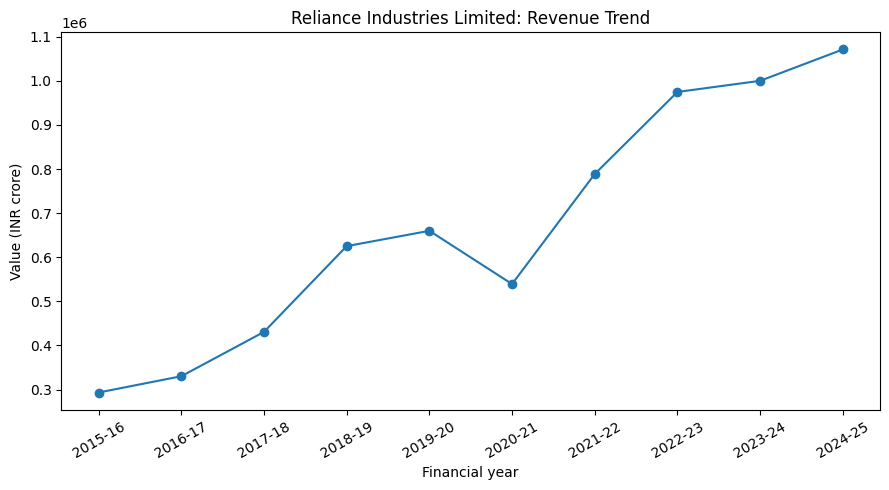

Company: Reliance Industries Limited
Metric: net_profit
Statement type: Consolidated
Unit: INR crore

Trend table:


,financial_year,value,change_from_previous,change_percent,document,page
0,2015-16,29861,NaN,NaN,RIL 10-Year Financial Highlights,Official website
1,2016-17,29833,-28.0,-0.09,RIL 10-Year Financial Highlights,Official website
2,2017-18,36080,6247.0,20.94,RIL 10-Year Financial Highlights,Official website
3,2018-19,39837,3757.0,10.41,RIL 10-Year Financial Highlights,Official website
4,2019-20,39880,43.0,0.11,RIL 10-Year Financial Highlights,Official website
5,2020-21,53739,13859.0,34.75,RIL 10-Year Financial Highlights,Official website
6,2021-22,66184,12445.0,23.16,RIL 10-Year Financial Highlights,Official website
7,2022-23,73670,7486.0,11.31,RIL 10-Year Financial Highlights,Official website
8,2023-24,79020,5350.0,7.26,RIL 10-Year Financial Highlights,Official website
9,2024-25,81309,2289.0,2.90,RIL 10-Year Financial Highlights,Official website


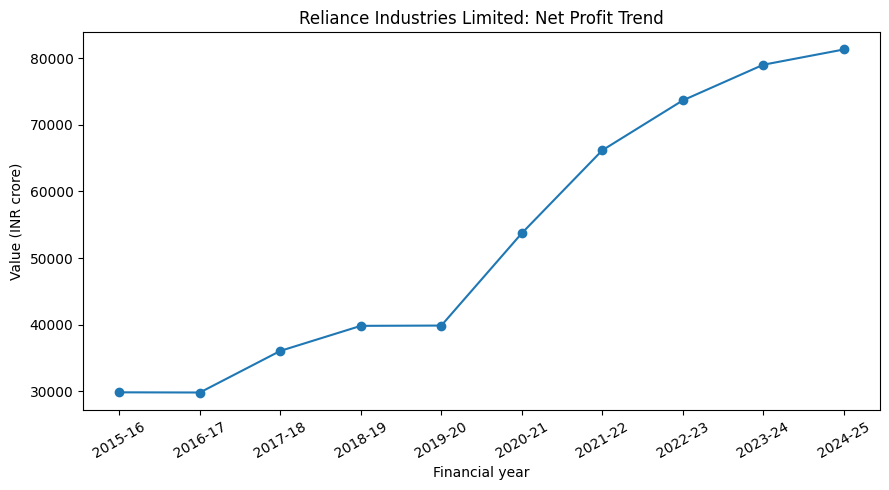

In [38]:

# CELL 35: Plot revenue and net profit trends

revenue_trend = analyze_financial_trends(
    financial_data,
    company="Reliance Industries Limited",
    metric="revenue",
    statement_type="Consolidated"
)

profit_trend = analyze_financial_trends(
    financial_data,
    company="Reliance Industries Limited",
    metric="net_profit",
    statement_type="Consolidated"
)


Financial growth analysis
Company: Reliance Industries Limited
Amounts: INR crore


,financial_year,revenue,net_profit,revenue_growth_pct,profit_growth_pct,net_profit_margin_pct
0,2015-16,293298,29861,NaN,NaN,10.18
1,2016-17,330180,29833,12.57,-0.09,9.04
2,2017-18,430731,36080,30.45,20.94,8.38
3,2018-19,625212,39837,45.15,10.41,6.37
4,2019-20,659997,39880,5.56,0.11,6.04
5,2020-21,539238,53739,-18.30,34.75,9.97
6,2021-22,788743,66184,46.27,23.16,8.39
7,2022-23,974864,73670,23.60,11.31,7.56
8,2023-24,1000122,79020,2.59,7.26,7.90
9,2024-25,1071174,81309,7.10,2.90,7.59


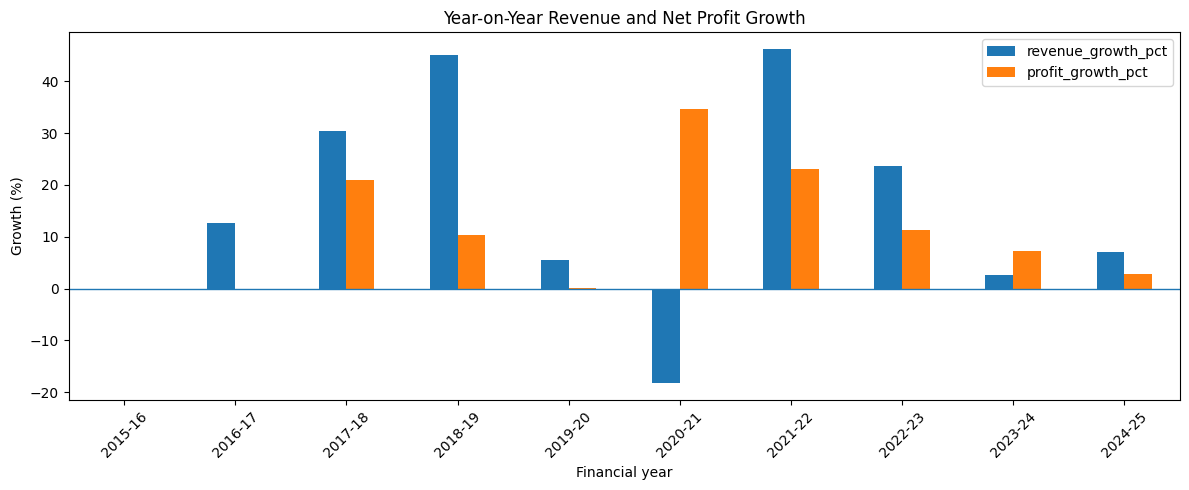

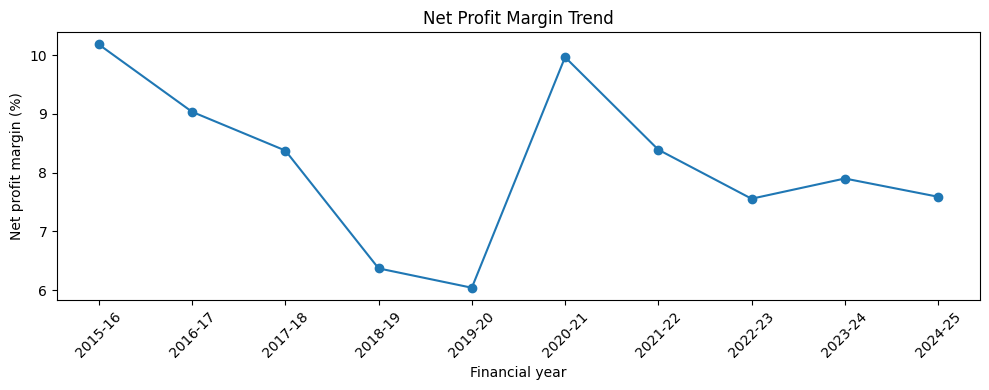

In [39]:

# CELL 36: Financial Growth and Profitability Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def calculate_growth_metrics(financial_data, company):
    data = financial_data[
        (financial_data["company"].str.strip().str.lower() == company.lower()) &
        (financial_data["verification_status"].str.strip().str.lower() == "verified") &
        (financial_data["statement_type"].str.strip().str.lower() == "consolidated")
    ].copy()

    data["value"] = pd.to_numeric(data["value"], errors="coerce")
    data = data.dropna(subset=["value"])

    revenue = data[data["metric"] == "revenue"][
        ["financial_year", "value"]
    ].rename(columns={"value": "revenue"})

    profit = data[data["metric"] == "net_profit"][
        ["financial_year", "value"]
    ].rename(columns={"value": "net_profit"})

    trends = revenue.merge(
        profit,
        on="financial_year",
        how="inner",
        validate="one_to_one"
    )

    if trends.empty:
        raise ValueError(
            "No matching revenue and profit data. Check Cell 34."
        )

    # Sort financial years in chronological order
    trends["_sort_year"] = trends["financial_year"].str[:4].astype(int)
    trends = trends.sort_values("_sort_year").drop(columns="_sort_year")

    trends["revenue_growth_pct"] = (
        trends["revenue"].pct_change() * 100
    )
    trends["profit_growth_pct"] = (
        trends["net_profit"].pct_change() * 100
    )
    trends["net_profit_margin_pct"] = (
        trends["net_profit"] / trends["revenue"] * 100
    )

    return trends.reset_index(drop=True)


growth_df = calculate_growth_metrics(
    financial_data,
    "Reliance Industries Limited"
)

print("Financial growth analysis")
print("Company: Reliance Industries Limited")
print("Amounts: INR crore")
display(growth_df.round(2))

# Plot year-on-year growth
growth_df.set_index("financial_year")[
    ["revenue_growth_pct", "profit_growth_pct"]
].plot(kind="bar", figsize=(12, 5))

plt.title("Year-on-Year Revenue and Net Profit Growth")
plt.xlabel("Financial year")
plt.ylabel("Growth (%)")
plt.xticks(rotation=45)
plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show()

# Plot profit margin
plt.figure(figsize=(10, 4))
plt.plot(
    growth_df["financial_year"],
    growth_df["net_profit_margin_pct"],
    marker="o"
)
plt.title("Net Profit Margin Trend")
plt.xlabel("Financial year")
plt.ylabel("Net profit margin (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [40]:

# CELL 37: FinSight AI Financial Dashboard

import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output, Markdown

# Reuse the growth data created in Cell 36
if "growth_df" not in globals() or growth_df.empty:
    raise ValueError("Run Cell 36 first.")

year_options = growth_df["financial_year"].tolist()

year_selector = widgets.Dropdown(
    options=year_options,
    value=year_options[-1],
    description="Financial year:"
)

dashboard_output = widgets.Output()

def render_dashboard(change=None):
    with dashboard_output:
        clear_output(wait=True)

        selected_year = year_selector.value
        row = growth_df.loc[
            growth_df["financial_year"] == selected_year
        ].iloc[0]

        display(Markdown("# FinSight AI"))
        display(Markdown("### Financial Performance Dashboard"))
        display(Markdown(
            f"**Company:** Reliance Industries Limited  \n"
            f"**Selected financial year:** {selected_year}  \n"
            f"**Amounts:** INR crore"
        ))

        kpis = pd.DataFrame({
            "Metric": [
                "Revenue",
                "Net Profit",
                "Revenue Growth (%)",
                "Profit Growth (%)",
                "Net Profit Margin (%)"
            ],
            "Value": [
                row["revenue"],
                row["net_profit"],
                row["revenue_growth_pct"],
                row["profit_growth_pct"],
                row["net_profit_margin_pct"]
            ]
        })

        display(kpis.round(2))

        # Revenue and profit trends
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))

        axes[0].plot(
            growth_df["financial_year"],
            growth_df["revenue"],
            marker="o"
        )
        axes[0].set_title("Revenue Trend")
        axes[0].set_ylabel("INR crore")
        axes[0].tick_params(axis="x", rotation=60)

        axes[1].plot(
            growth_df["financial_year"],
            growth_df["net_profit"],
            marker="o"
        )
        axes[1].set_title("Net Profit Trend")
        axes[1].set_ylabel("INR crore")
        axes[1].tick_params(axis="x", rotation=60)

        plt.tight_layout()
        plt.show()

        # Display source and data-quality caveat
        display(Markdown(
            "**Data quality note:** Figures currently come from the "
            "historical dataset entered earlier. Verify them against "
            "the official annual reports before presenting the results "
            "as audited or independently validated financial data."
        ))

year_selector.observe(render_dashboard, names="value")

display(year_selector, dashboard_output)
render_dashboard()


Dropdown(description='Financial year:', index=9, options=('2015-16', '2016-17', '2017-18', '2018-19', '2019-20…

Output()

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,TF-IDF + Logistic Regression,0.7221,0.6676,0.6867,0.6758
1,FinBERT,0.8771,0.8428,0.9049,0.8683



FinBERT classification report:
              precision    recall  f1-score   support

    negative       0.77      0.97      0.86       121
     neutral       0.95      0.85      0.90       575
    positive       0.80      0.90      0.85       272

    accuracy                           0.88       968
   macro avg       0.84      0.90      0.87       968
weighted avg       0.89      0.88      0.88       968



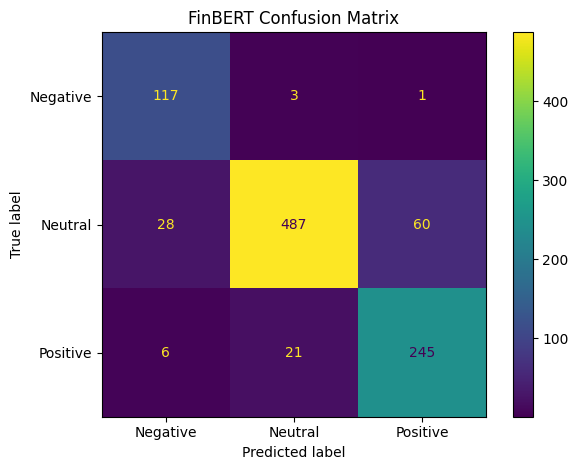

Evaluation saved to: /content/finsight_ai/processed/sentiment_model_evaluation.csv


In [41]:

# CELL 38: Sentiment Model Evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

labels = ["negative", "neutral", "positive"]

# Ensure both models have predictions
baseline_predictions = improved_model.predict(X_test_text)

if len(finbert_predictions) != len(y_test):
    raise ValueError("FinBERT predictions do not match the test set.")

y_true = y_test.astype(str).str.lower().tolist()

# Summary metrics
evaluation_summary = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": accuracy_score(y_true, baseline_predictions),
        "Macro Precision": precision_score(
            y_true, baseline_predictions,
            labels=labels, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, baseline_predictions,
            labels=labels, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, baseline_predictions,
            labels=labels, average="macro", zero_division=0
        )
    },
    {
        "Model": "FinBERT",
        "Accuracy": accuracy_score(y_true, finbert_predictions),
        "Macro Precision": precision_score(
            y_true, finbert_predictions,
            labels=labels, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, finbert_predictions,
            labels=labels, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, finbert_predictions,
            labels=labels, average="macro", zero_division=0
        )
    }
])

display(evaluation_summary.round(4))

print("\nFinBERT classification report:")
print(classification_report(
    y_true,
    finbert_predictions,
    labels=labels,
    zero_division=0
))

# Confusion matrix for FinBERT
ConfusionMatrixDisplay.from_predictions(
    y_true,
    finbert_predictions,
    labels=labels,
    display_labels=["Negative", "Neutral", "Positive"],
    values_format="d"
)

plt.title("FinBERT Confusion Matrix")
plt.tight_layout()
plt.show()

# Save evaluation metrics
evaluation_path = OUTPUT_DIR / "sentiment_model_evaluation.csv"
evaluation_summary.to_csv(evaluation_path, index=False)

print("Evaluation saved to:", evaluation_path)


Retrieval test completed.
Questions tested: 5
Passages retrieved: 25


,question,rank,page,similarity,text_excerpt
0,What does the report say about revenue?,1,40,0.556274,"Board’s Report Dear Members, The Board of Dire..."
1,What does the report say about revenue?,2,130,0.516233,Notes to the Consolidated Financial Statements...
2,What does the report say about revenue?,3,40,0.515545,"Disney”), by the transfer of the media and Jio..."
3,What does the report say about revenue?,4,77,0.509355,STANDALONE FINANCIAL STATEMENTS 151 Integrated...
4,What does the report say about revenue?,5,120,0.509169,"- 1,039 1,040 12 Payment to Key Managerial Per..."
5,What are the company's financial risks?,1,41,0.558901,he Annual Report on CSR activities including s...
6,What are the company's financial risks?,2,41,0.547731,"ation of risk management policy, key risks ide..."
7,What are the company's financial risks?,3,89,0.543583,"e risk management policy, the Company enters i..."
8,What are the company's financial risks?,4,128,0.532926,Notes to the Consolidated Financial Statements...
9,What are the company's financial risks?,5,14,0.517182,Risk and Governance Enterprise Risk Management...



Mean similarity score: 0.4979


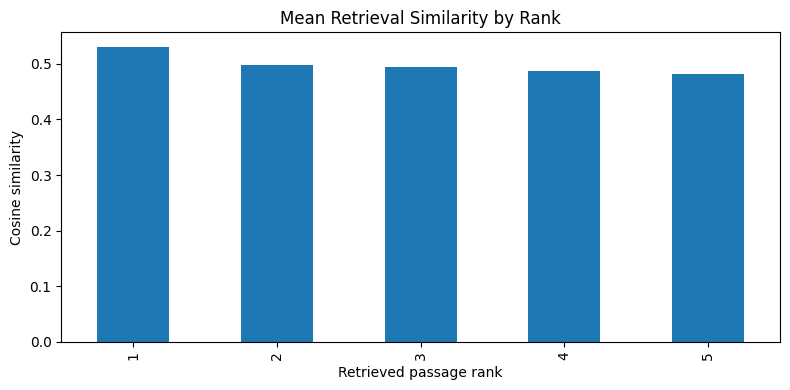


Results saved to: /content/finsight_ai/processed/retrieval_evaluation.csv


In [43]:

# CELL 39: Inspect semantic retrieval quality

import pandas as pd
import matplotlib.pyplot as plt

test_questions = [
    "What does the report say about revenue?",
    "What are the company's financial risks?",
    "What does the report say about debt and borrowings?",
    "What are the company's future business priorities?",
    "What does the report say about profit?"
]

retrieval_records = []

for question in test_questions:
    results = retrieve_financial_context(question, top_k=5)

    for rank, (_, row) in enumerate(results.iterrows(), start=1):
        retrieval_records.append({
            "question": question,
            "rank": rank,
            "document": row["document"],
            "page": int(row["page"]),
            "similarity": float(row["similarity"]),
            "text_excerpt": row["text"][:500]
        })

retrieval_evaluation_df = pd.DataFrame(retrieval_records)

print("Retrieval test completed.")
print("Questions tested:", len(test_questions))
print("Passages retrieved:", len(retrieval_evaluation_df))

display(
    retrieval_evaluation_df[
        ["question", "rank", "page", "similarity", "text_excerpt"]
    ]
)

print(
    "\nMean similarity score:",
    round(retrieval_evaluation_df["similarity"].mean(), 4)
)

# Plot similarity scores by rank
retrieval_evaluation_df.groupby("rank")["similarity"].mean().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Mean Retrieval Similarity by Rank")
plt.xlabel("Retrieved passage rank")
plt.ylabel("Cosine similarity")
plt.tight_layout()
plt.show()

retrieval_path = OUTPUT_DIR / "retrieval_evaluation.csv"
retrieval_evaluation_df.to_csv(retrieval_path, index=False)

print("\nResults saved to:", retrieval_path)


In [44]:

# CELL 40: FinSight AI Evaluation Summary

import pandas as pd
from IPython.display import display

evaluation_items = [
    {
        "Component": "TF-IDF Sentiment Baseline",
        "Evaluation": "Held-out test set",
        "Result": "Accuracy 72.21%; Macro F1 67.58%",
        "Status": "Evaluated"
    },
    {
        "Component": "FinBERT Sentiment",
        "Evaluation": "Held-out test set",
        "Result": "Accuracy 87.71%; Macro F1 86.83%",
        "Status": "Evaluated, dataset overlap caveat"
    },
    {
        "Component": "PDF Text Extraction",
        "Evaluation": "Extracted pages and sample text",
        "Result": "Check Cell 15 output",
        "Status": "Inspect output"
    },
    {
        "Component": "Semantic Retrieval",
        "Evaluation": "Top-5 passage inspection",
        "Result": "Check Cell 39 output",
        "Status": "Requires relevance labels"
    },
    {
        "Component": "RAG Question Answering",
        "Evaluation": "Manual source verification",
        "Result": "Check answer against cited pages",
        "Status": "Requires factual validation"
    },
    {
        "Component": "Financial Trend Analysis",
        "Evaluation": "Historical revenue and profit trends",
        "Result": "Depends on source-verified figures",
        "Status": "Verify financial data"
    },
    {
        "Component": "Financial Risk Assessment",
        "Evaluation": "Rule-based ratio screening",
        "Result": "Not a trained distress prediction model",
        "Status": "Requires verified balance-sheet data"
    }
]

project_evaluation = pd.DataFrame(evaluation_items)

display(project_evaluation)

summary_path = OUTPUT_DIR / "finsight_ai_evaluation_summary.csv"
project_evaluation.to_csv(summary_path, index=False)

print("\nEvaluation summary saved to:")
print(summary_path)

print("\nProject summary created.")


,Component,Evaluation,Result,Status
0,TF-IDF Sentiment Baseline,Held-out test set,Accuracy 72.21%; Macro F1 67.58%,Evaluated
1,FinBERT Sentiment,Held-out test set,Accuracy 87.71%; Macro F1 86.83%,"Evaluated, dataset overlap caveat"
2,PDF Text Extraction,Extracted pages and sample text,Check Cell 15 output,Inspect output
3,Semantic Retrieval,Top-5 passage inspection,Check Cell 39 output,Requires relevance labels
4,RAG Question Answering,Manual source verification,Check answer against cited pages,Requires factual validation
5,Financial Trend Analysis,Historical revenue and profit trends,Depends on source-verified figures,Verify financial data
6,Financial Risk Assessment,Rule-based ratio screening,Not a trained distress prediction model,Requires verified balance-sheet data



Evaluation summary saved to:
/content/finsight_ai/processed/finsight_ai_evaluation_summary.csv

Project summary created.


In [45]:

# CELL 41: Unified FinSight AI Interface

import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

# Interface elements
mode_selector = widgets.Dropdown(
    options=[
        ("Financial Sentiment Analysis", "sentiment"),
        ("Annual Report Q&A", "rag"),
        ("Financial Trends", "trends")
    ],
    value="sentiment",
    description="Feature:"
)

input_box = widgets.Textarea(
    value="The company reported strong revenue growth and improved profitability.",
    placeholder="Enter a financial statement or question...",
    description="Input:",
    layout=widgets.Layout(width="100%", height="100px")
)

run_button = widgets.Button(
    description="Run FinSight AI",
    button_style="primary",
    icon="play"
)

unified_output = widgets.Output()

def run_finsight(_):
    with unified_output:
        clear_output(wait=True)

        mode = mode_selector.value
        user_input = input_box.value.strip()

        try:
            if mode == "sentiment":
                if not user_input:
                    raise ValueError("Enter a financial statement.")

                result = predict_financial_sentiment(user_input)

                display(Markdown("# FinSight AI: Sentiment Analysis"))
                display(Markdown(f"**Statement:** {result['text']}"))
                display(Markdown(
                    f"**Predicted sentiment:** {result['sentiment'].upper()}"
                ))
                display(Markdown(
                    f"**Confidence:** {result['confidence']}%"
                ))

                display(Markdown("### Class probabilities"))
                display(pd.DataFrame([
                    {"Sentiment": label, "Probability (%)": score}
                    for label, score in result["probabilities"].items()
                ]).round(2))

            elif mode == "rag":
                if not user_input:
                    raise ValueError("Enter a question about the annual report.")

                result = ask_finsight(user_input, top_k=4)

                display(Markdown("# FinSight AI: Report Q&A"))
                display(Markdown(f"**Question:** {result['question']}"))
                display(Markdown(result["answer"]))
                display(Markdown("### Source passages"))

                for source in result["sources"]:
                    display(Markdown(
                        f"**{source['document']} | Page {source['page']}**\n\n"
                        f"> {source['text'][:600]}"
                    ))

            elif mode == "trends":
                display(Markdown("# FinSight AI: Financial Trends"))

                trend_data = calculate_growth_metrics(
                    financial_data,
                    "Reliance Industries Limited"
                )

                display(trend_data.round(2))

                display(Markdown(
                    "**Data note:** Verify historical figures against official "
                    "reports before treating the analysis as validated."
                ))

                trend_data.set_index("financial_year")[
                    ["revenue", "net_profit"]
                ].plot(
                    kind="line",
                    marker="o",
                    figsize=(10, 5)
                )

                import matplotlib.pyplot as plt
                plt.title("Reliance Industries: Revenue and Net Profit")
                plt.ylabel("INR crore")
                plt.tight_layout()
                plt.show()

        except Exception as error:
            display(Markdown(f"**Unable to complete the request:** `{error}`"))

run_button.on_click(run_finsight)

display(
    Markdown("# FinSight AI\nFinancial Document Intelligence and Risk Assessment"),
    mode_selector,
    input_box,
    run_button,
    unified_output
)


# FinSight AI
Financial Document Intelligence and Risk Assessment

Dropdown(description='Feature:', options=(('Financial Sentiment Analysis', 'sentiment'), ('Annual Report Q&A',…

Textarea(value='The company reported strong revenue growth and improved profitability.', description='Input:',…

Button(button_style='primary', description='Run FinSight AI', icon='play', style=ButtonStyle())

Output()

In [46]:

# CELL 42: Export FinSight AI Results

from pathlib import Path
import pandas as pd
import shutil
import zipfile

EXPORT_DIR = BASE_DIR / "project_export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Copy available output files into the export folder
for file_path in OUTPUT_DIR.iterdir():
    if file_path.is_file():
        shutil.copy2(file_path, EXPORT_DIR / file_path.name)

# Export financial trends if they exist
if "growth_df" in globals() and not growth_df.empty:
    growth_df.to_csv(
        EXPORT_DIR / "financial_growth_trends.csv",
        index=False
    )

# Export model comparison if it exists
if "evaluation_summary" in globals() and not evaluation_summary.empty:
    evaluation_summary.to_csv(
        EXPORT_DIR / "sentiment_model_comparison.csv",
        index=False
    )

# Create a manifest of exported files
manifest = pd.DataFrame([
    {
        "filename": path.name,
        "size_kb": round(path.stat().st_size / 1024, 2)
    }
    for path in EXPORT_DIR.iterdir()
    if path.is_file()
])

manifest.to_csv(EXPORT_DIR / "export_manifest.csv", index=False)

# Create ZIP archive
zip_path = BASE_DIR / "FinSight_AI_Project_Results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in EXPORT_DIR.iterdir():
        if path.is_file():
            archive.write(path, arcname=path.name)

print("Project export completed.")
print("Files exported:", len(manifest))
display(manifest)
print("\nZIP archive:", zip_path)


Project export completed.
Files exported: 13


,filename,size_kb
0,sentiment_model_comparison.csv,0.24
1,financial_value_review.csv,81.54
2,annual_report_embeddings.npy,1809.12
3,sentiment_model_evaluation.csv,0.24
4,annual_report_chunks.csv,1219.05
5,annual_report_pages.csv,919.24
6,financial_value_candidates.csv,79.13
7,financial_growth_trends.csv,0.81
8,retrieval_evaluation.csv,14.10
9,financial_statement_evidence.csv,382.58



ZIP archive: /content/finsight_ai/FinSight_AI_Project_Results.zip


In [47]:

from google.colab import files

files.download("/content/finsight_ai/FinSight_AI_Project_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:

# CELL 44: Save trained models and configuration

import joblib
import json
from pathlib import Path

MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete TF-IDF pipeline
joblib.dump(
    improved_model,
    MODEL_DIR / "tfidf_sentiment_pipeline.joblib"
)

# Save FinBERT tokenizer and model
finbert_model.save_pretrained(MODEL_DIR / "finbert")
finbert_tokenizer.save_pretrained(MODEL_DIR / "finbert")

# Save model metadata
model_info = {
    "project": "FinSight AI",
    "baseline_model": "TF-IDF + Logistic Regression",
    "baseline_test_accuracy": 0.7221,
    "baseline_macro_f1": 0.6758,
    "finbert_model": "ProsusAI/finbert",
    "finbert_test_accuracy": 0.8771,
    "finbert_macro_f1": 0.8683,
    "note": (
        "FinBERT metrics may be optimistic because its original "
        "fine-tuning data may overlap with the evaluation dataset."
    )
}

with open(MODEL_DIR / "model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

print("Models saved successfully.")
print("Model folder:", MODEL_DIR)
print("\nSaved files:")
for path in MODEL_DIR.rglob("*"):
    if path.is_file():
        print(path.relative_to(MODEL_DIR))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Models saved successfully.
Model folder: /content/finsight_ai/models

Saved files:
model_info.json
tfidf_sentiment_pipeline.joblib
finbert/config.json
finbert/tokenizer.json
finbert/tokenizer_config.json
finbert/model.safetensors


In [ ]:

# CELL 46: Generate FinSight AI README

from pathlib import Path

README = BASE_DIR / "README.md"

readme_content = """
# FinSight AI
## Financial Document Intelligence and Risk Assessment System

### Overview
FinSight AI is a prototype that combines financial sentiment analysis,
annual-report text extraction, semantic retrieval, RAG-based question
answering, and financial trend analysis.

### Main Components
1. Financial sentiment classification using FinBERT.
2. TF-IDF and Logistic Regression baseline.
3. PDF text extraction with document and page metadata.
4. Character-based document chunking.
5. Semantic retrieval using Sentence Transformers.
6. Question answering grounded in retrieved report passages.
7. Financial ratio screening and historical trend analysis.

### Sentiment Model Evaluation
| Model | Accuracy | Macro F1 |
|---|---:|---:|
| TF-IDF + Logistic Regression | 72.21% | 67.58% |
| FinBERT | 87.71% | 86.83% |

These metrics were calculated on a held-out split of Financial PhraseBank.
FinBERT may have been fine-tuned on overlapping data, so its score is not
necessarily an independent estimate of generalization.

### Data and Validation
- Annual-report text should be checked against the original PDF.
- RAG answers must be checked against their cited source pages.
- Financial figures must be verified for reporting year, statement type,
  units, and source before being used for ratios.
- Illustrative risk thresholds are not a validated bankruptcy model.
- No financial decision should rely solely on this prototype.

### Running the Notebook
Run the notebook cells in order. Install required libraries, load the
sentiment dataset, evaluate the models, download an annual report, extract
and chunk its text, build semantic embeddings, and test retrieval and Q&A.

### Suggested Future Improvements
- Evaluate on a separate financial sentiment dataset.
- Add labelled retrieval evaluation using Recall@k and MRR.
- Validate financial data extraction against audited statements.
- Add OCR support for scanned reports.
- Build a standalone web interface.
- Add tests, logging, and model/version tracking.
"""

README.write_text(readme_content.strip() + "\n", encoding="utf-8")

print("README created:", README)
print("\nPreview:\n")
print(README.read_text(encoding="utf-8")[:2500])


In [49]:

# CELL 48: Load the financial distress dataset

%pip -q install ucimlrepo

import pandas as pd
from ucimlrepo import fetch_ucirepo

# Fetch the official UCI dataset
bankruptcy_dataset = fetch_ucirepo(id=572)

# Separate features and target
distress_X = bankruptcy_dataset.data.features.copy()
distress_y = bankruptcy_dataset.data.targets.copy()

# Find the target column
target_column = distress_y.columns[0]

# Create a single working dataframe
distress_df = distress_X.copy()
distress_df["Bankrupt"] = distress_y[target_column].astype(int).values

print("Dataset loaded successfully!")
print("Number of companies:", distress_df.shape[0])
print("Number of columns:", distress_df.shape[1])
print("Number of input features:", distress_X.shape[1])

print("\nTarget distribution:")
print(distress_df["Bankrupt"].value_counts())
print("\nTarget proportions:")
print(
    (distress_df["Bankrupt"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

print("\nSample records:")
display(distress_df.head())


Dataset loaded successfully!
Number of companies: 6819
Number of columns: 96
Number of input features: 95

Target distribution:
Bankrupt
0    6599
1     220
Name: count, dtype: int64

Target proportions:
Bankrupt
0    96.77%
1     3.23%
Name: proportion, dtype: object

Sample records:


,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),...,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability,Bankrupt
0,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,...,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469,1
1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,...,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794,1
2,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,0.780284,...,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474,1
3,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,0.781241,...,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982,1
4,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,0.781550,...,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490,1


In [50]:

# CELL 49: Data quality checks and preparation

import numpy as np
import pandas as pd

# Confirm the previous cell ran successfully
if "distress_df" not in globals():
    raise ValueError("Run Cell 48 first to load the dataset.")

# Separate features and target
target_col = "Bankrupt"

distress_X = distress_df.drop(columns=[target_col]).copy()
distress_y = distress_df[target_col].copy()

# Convert all input features to numeric
distress_X = distress_X.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with missing values
distress_X = distress_X.replace([np.inf, -np.inf], np.nan)

print("Dataset shape:", distress_df.shape)
print("Duplicate rows:", distress_df.duplicated().sum())
print("Duplicate feature rows:", distress_X.duplicated().sum())
print("Missing feature values:", int(distress_X.isna().sum().sum()))
print("Infinite feature values:", int(np.isinf(distress_X.to_numpy()).sum()))

print("\nTarget values:")
print(distress_y.value_counts(dropna=False))

print("\nFeatures with most missing values:")
display(
    distress_X.isna().sum()
    .sort_values(ascending=False)
    .head(10)
    .rename("missing_count")
    .to_frame()
)

print("\nFeature summary:")
display(distress_X.describe().T.head(10))

# Keep feature names for the model and later explainability
feature_names = distress_X.columns.tolist()

print("\nNumber of input features:", len(feature_names))
print("Data inspection completed.")


Dataset shape: (6819, 96)
Duplicate rows: 0
Duplicate feature rows: 0
Missing feature values: 0
Infinite feature values: 0

Target values:
Bankrupt
0    6599
1     220
Name: count, dtype: int64

Features with most missing values:


,missing_count
ROA(C) before interest and depreciation before interest,0
ROA(A) before interest and % after tax,0
ROA(B) before interest and depreciation after tax,0
Operating Gross Margin,0
Realized Sales Gross Margin,0
Operating Profit Rate,0
Pre-tax net Interest Rate,0
After-tax net Interest Rate,0
Non-industry income and expenditure/revenue,0
Continuous interest rate (after tax),0



Feature summary:


,count,mean,std,min,25%,50%,75%,max
ROA(C) before interest and depreciation before interest,6819.0,0.505180,0.060686,0.0,0.476527,0.502706,0.535563,1.0
ROA(A) before interest and % after tax,6819.0,0.558625,0.065620,0.0,0.535543,0.559802,0.589157,1.0
ROA(B) before interest and depreciation after tax,6819.0,0.553589,0.061595,0.0,0.527277,0.552278,0.584105,1.0
Operating Gross Margin,6819.0,0.607948,0.016934,0.0,0.600445,0.605997,0.613914,1.0
Realized Sales Gross Margin,6819.0,0.607929,0.016916,0.0,0.600434,0.605976,0.613842,1.0
Operating Profit Rate,6819.0,0.998755,0.013010,0.0,0.998969,0.999022,0.999095,1.0
Pre-tax net Interest Rate,6819.0,0.797190,0.012869,0.0,0.797386,0.797464,0.797579,1.0
After-tax net Interest Rate,6819.0,0.809084,0.013601,0.0,0.809312,0.809375,0.809469,1.0
Non-industry income and expenditure/revenue,6819.0,0.303623,0.011163,0.0,0.303466,0.303525,0.303585,1.0
Continuous interest rate (after tax),6819.0,0.781381,0.012679,0.0,0.781567,0.781635,0.781735,1.0



Number of input features: 95
Data inspection completed.


TRAINING AND TESTING COMPLETE
Training records: 5455
Test records: 1364
Number of features: 95

Baseline evaluation:


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (Average Precision)
0,Logistic Regression,0.8783,0.8492,0.1856,0.8182,0.3025,0.9171,0.319



Classification report:
              precision    recall  f1-score   support

Not Bankrupt       0.99      0.88      0.93      1320
    Bankrupt       0.19      0.82      0.30        44

    accuracy                           0.88      1364
   macro avg       0.59      0.85      0.62      1364
weighted avg       0.97      0.88      0.91      1364



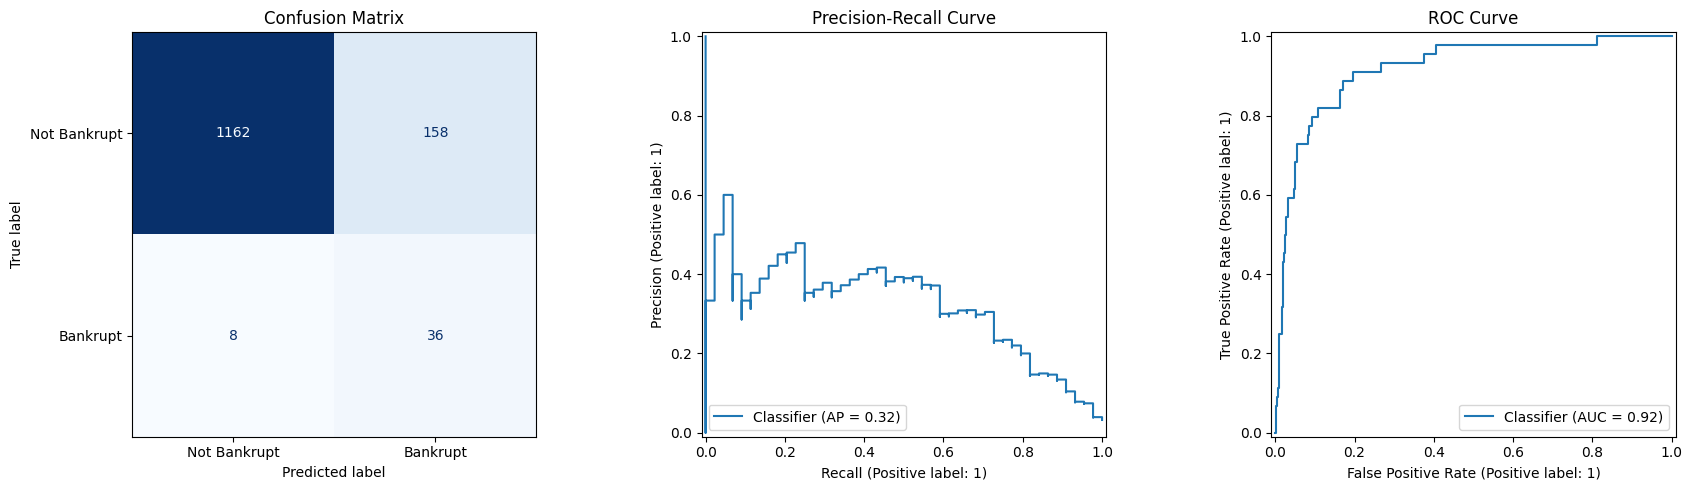


Saved baseline metrics to:
/content/finsight_ai/processed/distress_baseline_metrics.csv


In [51]:

# CELL 50: Baseline Financial Distress Prediction Model

%pip -q install scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, PrecisionRecallDisplay,
    RocCurveDisplay
)

# Confirm the previous cells ran
if "distress_df" not in globals():
    raise ValueError("Run Cells 48 and 49 first.")

TARGET = "Bankrupt"

X = distress_df.drop(columns=[TARGET]).copy()
y = pd.to_numeric(distress_df[TARGET], errors="coerce")

# Clean feature data
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

# Remove rows with missing target labels, if any
valid_rows = y.notna()
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].astype(int).reset_index(drop=True)

# Stratified split preserves the rare bankruptcy class
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# All preprocessing is inside the pipeline
baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

baseline_model.fit(X_train, y_train)

# Evaluate using the untouched test set
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

baseline_metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC (Average Precision)": average_precision_score(y_test, y_prob)
}

baseline_results = pd.DataFrame([baseline_metrics])

print("TRAINING AND TESTING COMPLETE")
print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Number of features:", X.shape[1])
print("\nBaseline evaluation:")
display(baseline_results.round(4))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Not Bankrupt", "Bankrupt"],
    zero_division=0
))

# Visual diagnostics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Not Bankrupt", "Bankrupt"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Confusion Matrix")

PrecisionRecallDisplay.from_predictions(
    y_test, y_prob, ax=axes[1]
)
axes[1].set_title("Precision-Recall Curve")

RocCurveDisplay.from_predictions(
    y_test, y_prob, ax=axes[2]
)
axes[2].set_title("ROC Curve")

plt.tight_layout()
plt.show()

# Save the baseline results for the final project report
from pathlib import Path

PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
MODELS_DIR = PROJECT_DIR / "models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(
    PROCESSED_DIR / "distress_baseline_metrics.csv",
    index=False
)

print("\nSaved baseline metrics to:")
print(PROCESSED_DIR / "distress_baseline_metrics.csv")


XGBoost available.

Cross-validating Logistic Regression...

Cross-validating Random Forest...

Cross-validating XGBoost...

Training cross-validation results:


,Model,OOF PR-AUC,OOF ROC-AUC
0,XGBoost,0.4167,0.9315
1,Random Forest,0.3992,0.9365
2,Logistic Regression,0.3078,0.8858



Selected model: XGBoost
Selected threshold: 0.5858
Training OOF precision: 0.3855
Training OOF recall: 0.6023
Training OOF F1: 0.4701

Held-out test results:


,Model,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,0.5858,0.9545,0.8447,0.3902,0.7273,0.5079,0.9518,0.4931



Classification report:
              precision    recall  f1-score   support

Not Bankrupt       0.99      0.96      0.98      1320
    Bankrupt       0.39      0.73      0.51        44

    accuracy                           0.95      1364
   macro avg       0.69      0.84      0.74      1364
weighted avg       0.97      0.95      0.96      1364



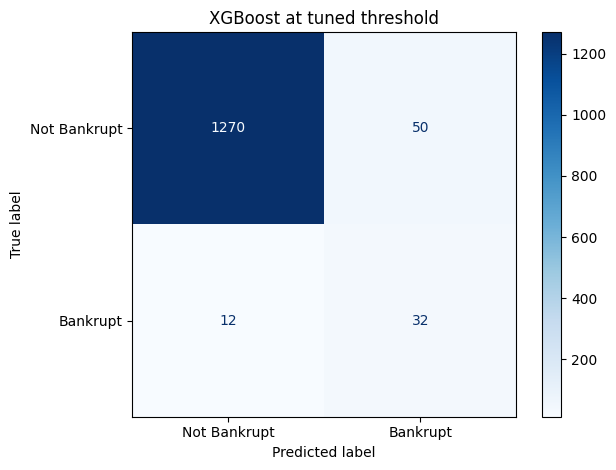


Saved tuned model, threshold configuration and evaluation results.
The test set was not used to select the model or threshold.


In [53]:

# CELL 53: Rebuild Models, Cross-Validate and Tune Threshold

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, precision_recall_curve
)
from pathlib import Path

# 1. Check required data from Cell 50
required = ["X_train", "X_test", "y_train", "y_test"]
missing = [name for name in required if name not in globals()]

if missing:
    raise ValueError(
        f"Missing variables: {missing}. Run Cell 50 successfully first."
    )

# 2. Rebuild candidate models without relying on Cell 51 variables
models_to_compare = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# Add XGBoost if available and install succeeds
try:
    from xgboost import XGBClassifier

    negatives = int((y_train == 0).sum())
    positives = int((y_train == 1).sum())

    models_to_compare["XGBoost"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.04,
            subsample=0.85,
            colsample_bytree=0.85,
            scale_pos_weight=negatives / max(positives, 1),
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
    print("XGBoost available.")
except ImportError:
    print("XGBoost not installed; comparing Logistic Regression and Random Forest.")

# 3. Cross-validated probabilities using training data only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probabilities = {}
cv_rows = []

for name, model in models_to_compare.items():
    print(f"\nCross-validating {name}...")

    probabilities = cross_val_predict(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    oof_probabilities[name] = probabilities

    cv_rows.append({
        "Model": name,
        "OOF PR-AUC": average_precision_score(y_train, probabilities),
        "OOF ROC-AUC": roc_auc_score(y_train, probabilities)
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    "OOF PR-AUC", ascending=False
).reset_index(drop=True)

print("\nTraining cross-validation results:")
display(cv_results.round(4))

# 4. Choose model using training OOF PR-AUC
best_name = cv_results.iloc[0]["Model"]
best_oof_prob = oof_probabilities[best_name]
best_model = clone(models_to_compare[best_name])

# Choose threshold using training OOF predictions only
precision, recall, thresholds = precision_recall_curve(
    y_train, best_oof_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    np.maximum(precision[:-1] + recall[:-1], 1e-12)
)

threshold_index = int(np.argmax(f1_scores))
best_threshold = float(thresholds[threshold_index])

print("\nSelected model:", best_name)
print(f"Selected threshold: {best_threshold:.4f}")
print(f"Training OOF precision: {precision[threshold_index]:.4f}")
print(f"Training OOF recall: {recall[threshold_index]:.4f}")
print(f"Training OOF F1: {f1_scores[threshold_index]:.4f}")

# 5. Fit selected model on training data and evaluate on test data
best_model.fit(X_train, y_train)

test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

final_metrics = pd.DataFrame([{
    "Model": best_name,
    "Threshold": best_threshold,
    "Accuracy": (test_predictions == np.asarray(y_test)).mean(),
    "Balanced Accuracy": balanced_accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities)
}])

print("\nHeld-out test results:")
display(final_metrics.round(4))

print("\nClassification report:")
print(classification_report(
    y_test, test_predictions,
    target_names=["Not Bankrupt", "Bankrupt"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    display_labels=["Not Bankrupt", "Bankrupt"],
    cmap="Blues",
    values_format="d"
)
plt.title(f"{best_name} at tuned threshold")
plt.tight_layout()
plt.show()

# 6. Save model and results
PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
MODELS_DIR = PROJECT_DIR / "models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(PROCESSED_DIR / "distress_cross_validation.csv", index=False)
final_metrics.to_csv(PROCESSED_DIR / "distress_tuned_metrics.csv", index=False)

joblib.dump(best_model, MODELS_DIR / "financial_distress_model_tuned.joblib")
joblib.dump({
    "model_name": best_name,
    "threshold": best_threshold,
    "feature_names": list(X_train.columns)
}, MODELS_DIR / "financial_distress_model_config.joblib")

print("\nSaved tuned model, threshold configuration and evaluation results.")
print("The test set was not used to select the model or threshold.")


,Threshold,True Positives,False Positives,True Negatives,False Negatives,Precision,Recall,F1
0,0.3000,36,100,1220,8,0.2647,0.8182,0.4000
1,0.4000,36,84,1236,8,0.3000,0.8182,0.4390
2,0.4500,35,71,1249,9,0.3302,0.7955,0.4667
3,0.5000,34,62,1258,10,0.3542,0.7727,0.4857
4,0.5500,32,53,1267,12,0.3765,0.7273,0.4961
5,0.5858,32,50,1270,12,0.3902,0.7273,0.5079
6,0.6000,32,50,1270,12,0.3902,0.7273,0.5079
7,0.6500,27,45,1275,17,0.3750,0.6136,0.4655
8,0.7000,27,39,1281,17,0.4091,0.6136,0.4909
9,0.7500,26,33,1287,18,0.4407,0.5909,0.5049


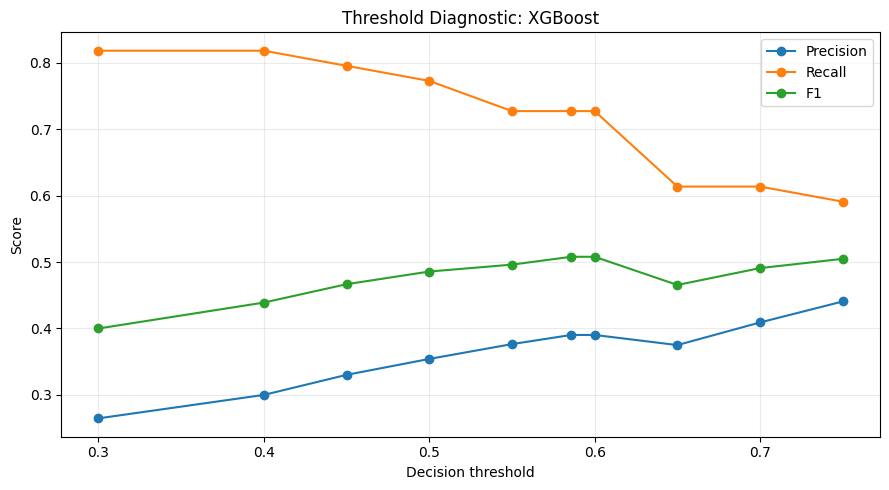

Diagnostic only: do not select the final threshold from this test-set table.


In [54]:

# CELL 54: Analyze the Precision-Recall Trade-off

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the tuned model and test probabilities from Cell 53
if "test_probabilities" not in globals() or "y_test" not in globals():
    raise ValueError("Run Cell 53 successfully first.")

thresholds_to_inspect = [
    0.30, 0.40, 0.45, 0.50, 0.55, 0.5858, 0.60, 0.65, 0.70, 0.75
]

rows = []

for threshold in thresholds_to_inspect:
    predictions = (test_probabilities >= threshold).astype(int)

    tp = int(((predictions == 1) & (np.asarray(y_test) == 1)).sum())
    fp = int(((predictions == 1) & (np.asarray(y_test) == 0)).sum())
    fn = int(((predictions == 0) & (np.asarray(y_test) == 1)).sum())
    tn = int(((predictions == 0) & (np.asarray(y_test) == 0)).sum())

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "Threshold": threshold,
        "True Positives": tp,
        "False Positives": fp,
        "True Negatives": tn,
        "False Negatives": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_results = pd.DataFrame(rows)

display(threshold_results.round(4))

threshold_results.to_csv(
    PROCESSED_DIR / "distress_threshold_diagnostic.csv",
    index=False
)

plt.figure(figsize=(9, 5))
plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1"
)
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Threshold Diagnostic: XGBoost")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Diagnostic only: do not select the final threshold from this test-set table.")


Explaining model: XGBoost
Background records: 100
Records being explained: 250

Top 20 features influencing model predictions:


,Feature,Mean_Absolute_SHAP
39,Borrowing dependency,0.549089
35,Total debt/Total net worth,0.491116
9,Continuous interest rate (after tax),0.464670
33,Quick Ratio,0.435664
13,Interest-bearing debt interest rate,0.342081
18,Persistent EPS in the Last Four Seasons,0.331839
52,Allocation rate per person,0.260725
0,ROA(C) before interest and depreciation befor...,0.248686
2,ROA(B) before interest and depreciation after...,0.247220
58,Cash/Current Liability,0.227154


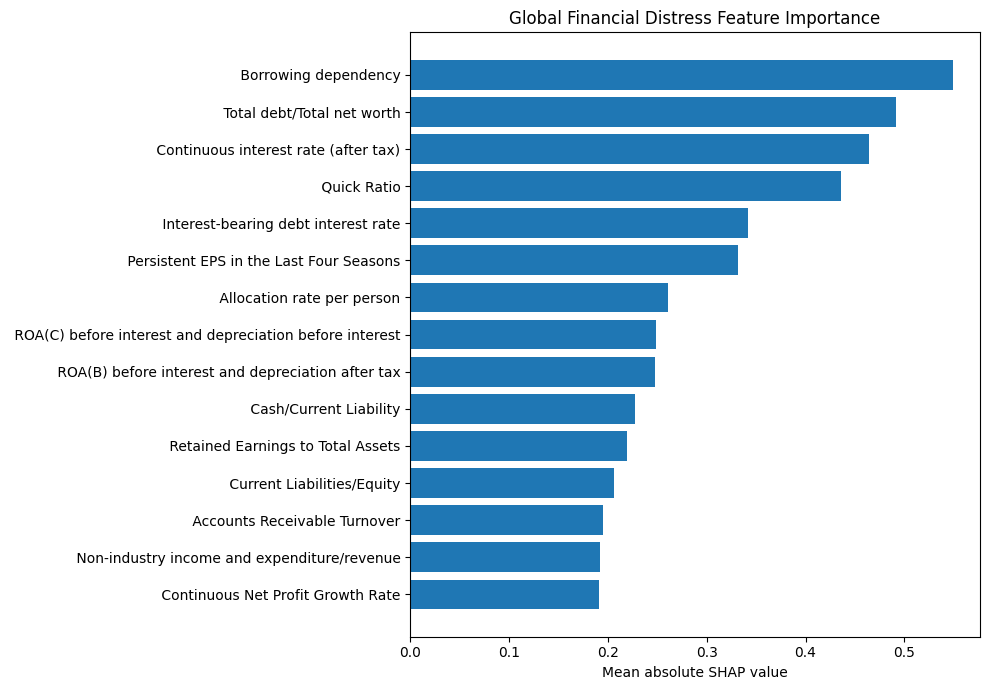

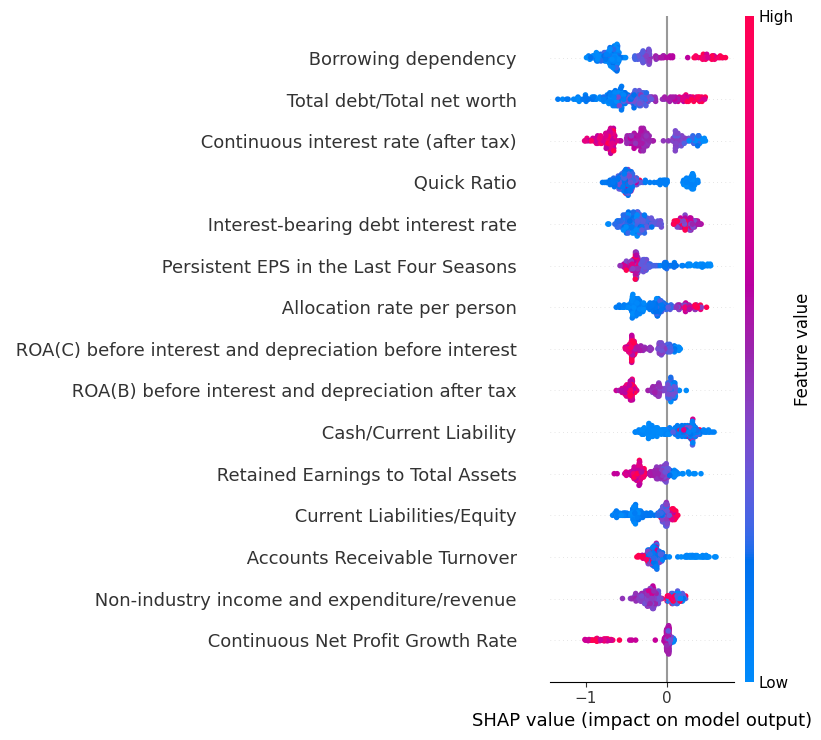


Saved SHAP importance to:
/content/finsight_ai/processed/distress_shap_feature_importance.csv

Interpretation note: SHAP explains this model's predictions; it does not establish that a feature causes bankruptcy.


In [55]:

# CELL 55: Explain Financial Distress Predictions with SHAP

%pip -q install shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from pathlib import Path

# Use the final tuned model from Cell 53
if "best_model" not in globals():
    raise ValueError("Run Cell 53 successfully first.")

if "X_train" not in globals() or "X_test" not in globals():
    raise ValueError("Training and test data are missing. Run Cell 50 first.")

# Get the fitted classifier and transform data through the model pipeline
classifier = best_model.named_steps["classifier"]
preprocessor_steps = list(best_model.steps[:-1])

def transform_for_shap(data):
    transformed = data.copy()
    for step_name, transformer in preprocessor_steps:
        transformed = transformer.transform(transformed)

    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()

    return np.asarray(transformed)

X_train_transformed = transform_for_shap(X_train)
X_test_transformed = transform_for_shap(X_test)

# Feature names remain in their original order
feature_names = list(X_train.columns)

# Use a manageable background and explanation sample
rng = np.random.default_rng(42)
background_size = min(100, len(X_train_transformed))
explain_size = min(250, len(X_test_transformed))

background_indices = rng.choice(
    len(X_train_transformed),
    size=background_size,
    replace=False
)

explain_indices = rng.choice(
    len(X_test_transformed),
    size=explain_size,
    replace=False
)

background = X_train_transformed[background_indices]
X_explain = X_test_transformed[explain_indices]

print("Explaining model:", globals().get("best_name", "Selected model"))
print("Background records:", len(background))
print("Records being explained:", len(X_explain))

# TreeExplainer is appropriate for XGBoost and Random Forest.
# Logistic Regression uses a model-agnostic fallback.
try:
    if classifier.__class__.__name__ in ["XGBClassifier", "RandomForestClassifier"]:
        explainer = shap.TreeExplainer(classifier)
        shap_values = explainer.shap_values(X_explain)
    else:
        explainer = shap.Explainer(
            classifier.predict_proba,
            background
        )
        shap_values = explainer(X_explain)
except Exception as e:
    print("Tree explanation fallback:", str(e)[:250])
    explainer = shap.Explainer(
        classifier.predict_proba,
        background
    )
    shap_values = explainer(X_explain)

# Normalize SHAP outputs across SHAP versions and binary classifiers
if isinstance(shap_values, list):
    # Older SHAP versions may return one array per class
    values = shap_values[1] if len(shap_values) > 1 else shap_values[0]
elif hasattr(shap_values, "values"):
    values = shap_values.values
else:
    values = shap_values

values = np.asarray(values)

# Some explainers return (samples, features, classes)
if values.ndim == 3:
    values = values[:, :, 1] if values.shape[-1] > 1 else values[:, :, 0]

if values.ndim != 2:
    raise ValueError(
        f"Unexpected SHAP array shape: {values.shape}. "
        "Inspect the installed SHAP version and explainer output."
    )

# Global importance: average absolute SHAP contribution
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

print("\nTop 20 features influencing model predictions:")
display(shap_importance.head(20))

# Global importance plot
top_n = 15
plot_data = shap_importance.head(top_n).sort_values("Mean_Absolute_SHAP")

plt.figure(figsize=(10, 7))
plt.barh(
    plot_data["Feature"],
    plot_data["Mean_Absolute_SHAP"]
)
plt.xlabel("Mean absolute SHAP value")
plt.title("Global Financial Distress Feature Importance")
plt.tight_layout()
plt.show()

# Beeswarm plot shows direction and magnitude of feature effects
shap.summary_plot(
    values,
    X_explain,
    feature_names=feature_names,
    max_display=15,
    show=True
)

# Save explainability results
PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

shap_importance.to_csv(
    PROCESSED_DIR / "distress_shap_feature_importance.csv",
    index=False
)

print("\nSaved SHAP importance to:")
print(PROCESSED_DIR / "distress_shap_feature_importance.csv")
print(
    "\nInterpretation note: SHAP explains this model's predictions; "
    "it does not establish that a feature causes bankruptcy."
)


Training records: 5455
Test records held out: 1364
Bankruptcy class weight baseline: 29.99

Starting randomized hyperparameter search...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best cross-validated PR-AUC: 0.4691

Best hyperparameters:
{'classifier__subsample': 0.85, 'classifier__scale_pos_weight': 37.49289772727273, 'classifier__reg_lambda': 10, 'classifier__reg_alpha': 1.0, 'classifier__n_estimators': 700, 'classifier__min_child_weight': 3, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.85}


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
22,1,0.4691,0.0736,1.0000,"{'classifier__subsample': 0.85, 'classifier__s..."
5,2,0.4640,0.0766,0.9936,"{'classifier__subsample': 0.7, 'classifier__sc..."
20,3,0.4629,0.0601,0.9991,"{'classifier__subsample': 0.7, 'classifier__sc..."
23,4,0.4623,0.0766,1.0000,"{'classifier__subsample': 1.0, 'classifier__sc..."
1,5,0.4617,0.0796,1.0000,"{'classifier__subsample': 1.0, 'classifier__sc..."
18,6,0.4560,0.0702,0.9363,"{'classifier__subsample': 0.85, 'classifier__s..."
2,7,0.4555,0.0790,1.0000,"{'classifier__subsample': 0.85, 'classifier__s..."
11,8,0.4529,0.0785,0.9991,"{'classifier__subsample': 0.7, 'classifier__sc..."
10,9,0.4497,0.0726,0.9950,"{'classifier__subsample': 0.7, 'classifier__sc..."
0,10,0.4484,0.0808,1.0000,"{'classifier__subsample': 1.0, 'classifier__sc..."



TUNED MODEL RESULTS


,Model,CV PR-AUC,Test Accuracy,Test Balanced Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC
0,Tuned XGBoost,0.4691,0.9677,0.7527,0.5,0.5227,0.5111,0.9584,0.5176



Classification report at threshold 0.5:
              precision    recall  f1-score   support

Not Bankrupt       0.98      0.98      0.98      1320
    Bankrupt       0.50      0.52      0.51        44

    accuracy                           0.97      1364
   macro avg       0.74      0.75      0.75      1364
weighted avg       0.97      0.97      0.97      1364



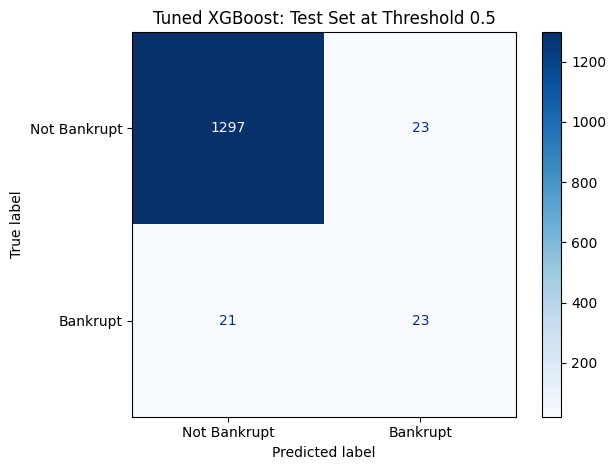


Saved tuned model and search results.
Compare its Test PR-AUC with the earlier 0.4931 baseline.
A higher score is not guaranteed; cross-validation helps us choose honestly.


In [56]:

# CELL 56: Tune XGBoost with Training-Only Cross-Validation

%pip -q install xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

# Check required variables
required = ["X_train", "X_test", "y_train", "y_test"]
missing = [name for name in required if name not in globals()]
if missing:
    raise ValueError(f"Run Cell 50 successfully first. Missing: {missing}")

# Convert targets to NumPy arrays for reliable indexing
y_train_arr = np.asarray(y_train, dtype=int)
y_test_arr = np.asarray(y_test, dtype=int)

negative_count = int((y_train_arr == 0).sum())
positive_count = int((y_train_arr == 1).sum())
base_weight = negative_count / max(positive_count, 1)

# Keep imputation inside the pipeline to avoid leakage
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
        tree_method="hist"
    ))
])

param_distributions = {
    "classifier__n_estimators": [200, 350, 500, 700],
    "classifier__max_depth": [2, 3, 4, 5],
    "classifier__learning_rate": [0.015, 0.03, 0.05, 0.08],
    "classifier__min_child_weight": [1, 3, 5, 8],
    "classifier__subsample": [0.7, 0.85, 1.0],
    "classifier__colsample_bytree": [0.7, 0.85, 1.0],
    "classifier__reg_lambda": [1, 3, 5, 10],
    "classifier__reg_alpha": [0, 0.1, 0.5, 1.0],
    "classifier__scale_pos_weight": [
        base_weight * 0.5,
        base_weight * 0.75,
        base_weight,
        base_weight * 1.25
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=24,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True,
    return_train_score=True
)

print("Training records:", len(X_train))
print("Test records held out:", len(X_test))
print("Bankruptcy class weight baseline:", round(base_weight, 2))
print("\nStarting randomized hyperparameter search...")

search.fit(X_train, y_train_arr)

tuning_results = pd.DataFrame(search.cv_results_).sort_values(
    "rank_test_score"
)

print("\nBest cross-validated PR-AUC:", round(search.best_score_, 4))
print("\nBest hyperparameters:")
print(search.best_params_)

display(
    tuning_results[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params"
        ]
    ].head(10).round(4)
)

# Evaluate the chosen configuration on the held-out test set ONCE
tuned_xgb_model = search.best_estimator_
tuned_test_prob = tuned_xgb_model.predict_proba(X_test)[:, 1]

# Use the standard 0.5 threshold for this model comparison.
# Threshold optimization will be done separately using training OOF predictions.
tuned_test_pred = (tuned_test_prob >= 0.5).astype(int)

tuned_test_metrics = pd.DataFrame([{
    "Model": "Tuned XGBoost",
    "CV PR-AUC": search.best_score_,
    "Test Accuracy": (tuned_test_pred == y_test_arr).mean(),
    "Test Balanced Accuracy": balanced_accuracy_score(
        y_test_arr, tuned_test_pred
    ),
    "Test Precision": precision_score(
        y_test_arr, tuned_test_pred, zero_division=0
    ),
    "Test Recall": recall_score(
        y_test_arr, tuned_test_pred, zero_division=0
    ),
    "Test F1": f1_score(
        y_test_arr, tuned_test_pred, zero_division=0
    ),
    "Test ROC-AUC": roc_auc_score(y_test_arr, tuned_test_prob),
    "Test PR-AUC": average_precision_score(
        y_test_arr, tuned_test_prob
    )
}])

print("\nTUNED MODEL RESULTS")
display(tuned_test_metrics.round(4))

print("\nClassification report at threshold 0.5:")
print(classification_report(
    y_test_arr,
    tuned_test_pred,
    target_names=["Not Bankrupt", "Bankrupt"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_arr,
    tuned_test_pred,
    display_labels=["Not Bankrupt", "Bankrupt"],
    cmap="Blues",
    values_format="d"
)
plt.title("Tuned XGBoost: Test Set at Threshold 0.5")
plt.tight_layout()
plt.show()

# Save tuning artifacts
PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
MODELS_DIR = PROJECT_DIR / "models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

tuned_test_metrics.to_csv(
    PROCESSED_DIR / "distress_xgboost_tuned_metrics.csv",
    index=False
)

tuning_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "params"
    ]
].to_csv(
    PROCESSED_DIR / "distress_xgboost_search_results.csv",
    index=False
)

joblib.dump(
    tuned_xgb_model,
    MODELS_DIR / "financial_distress_xgboost_tuned.joblib"
)

print("\nSaved tuned model and search results.")
print("Compare its Test PR-AUC with the earlier 0.4931 baseline.")
print("A higher score is not guaranteed; cross-validation helps us choose honestly.")


In [57]:

# CELL 57: Compare Previous and Tuned XGBoost on the Same Test Set

import pandas as pd
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

if "tuned_xgb_model" not in globals():
    raise ValueError("Run Cell 56 successfully first.")

if "X_test" not in globals() or "y_test" not in globals():
    raise ValueError("Run Cell 50 successfully first.")

y_true = np.asarray(y_test, dtype=int)

models_to_evaluate = {
    "Tuned XGBoost": tuned_xgb_model
}

# Add the previous candidate if available
if "best_model" in globals():
    models_to_evaluate["Previous selected model"] = best_model

rows = []

for name, model in models_to_evaluate.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    rows.append({
        "Model": name,
        "Threshold": 0.5,
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities)
    })

comparison = pd.DataFrame(rows).sort_values(
    "PR-AUC", ascending=False
)

display(comparison.round(4))

comparison.to_csv(
    PROCESSED_DIR / "distress_final_model_comparison.csv",
    index=False
)

print("Comparison saved.")
print("Use PR-AUC and recall alongside precision to judge the model.")


,Model,Threshold,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC
0,Tuned XGBoost,0.5,0.5000,0.5227,0.5111,0.7527,0.9584,0.5176
1,Previous selected model,0.5,0.3542,0.7727,0.4857,0.8629,0.9518,0.4931


Comparison saved.
Use PR-AUC and recall alongside precision to judge the model.


Generating out-of-fold training predictions...

Training-only threshold selection
OOF PR-AUC: 0.4549
OOF ROC-AUC: 0.9386
Selected threshold: 0.4106
OOF precision at selected threshold: 0.4742
OOF recall at selected threshold: 0.5227
OOF F1 at selected threshold: 0.4973

Alternative threshold options from training data:


,Selection goal,Threshold,OOF Precision,OOF Recall,OOF F1
0,Recall >= 60%,0.2399,0.3970,0.6023,0.4786
1,Recall >= 70%,0.0654,0.2780,0.7045,0.3987
2,Recall >= 80%,0.0249,0.2284,0.8125,0.3566
3,Recall >= 90%,0.0058,0.1619,0.9034,0.2746


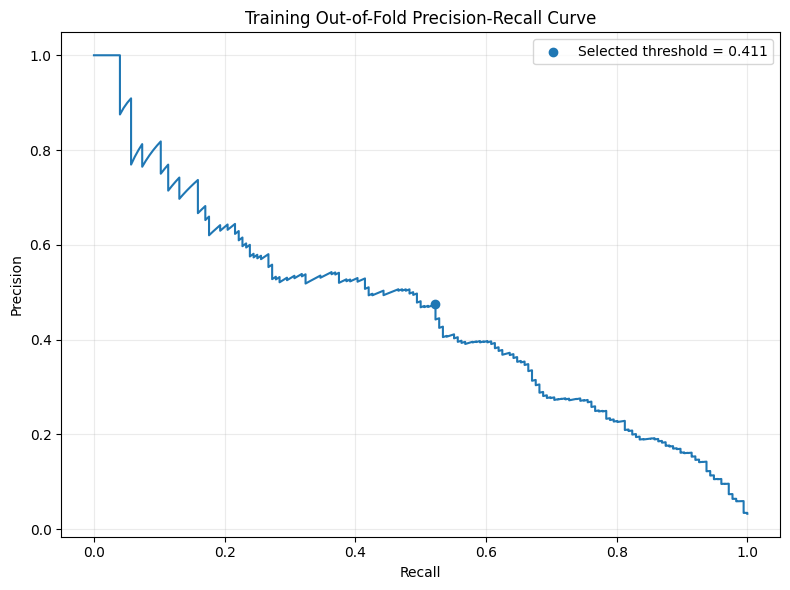


Saved final threshold configuration.
Cell 59 will fit the selected model on all training data and evaluate the test set.


In [58]:

# CELL 58: Select Final Decision Threshold Without Test-Set Leakage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    roc_auc_score
)

# Confirm required objects exist
required = ["search", "X_train", "y_train", "X_test", "y_test"]
missing = [name for name in required if name not in globals()]
if missing:
    raise ValueError(
        f"Missing variables: {missing}. Run Cells 50 and 56 successfully first."
    )

# Use the best estimator found by training-only cross-validation
threshold_model = clone(search.best_estimator_)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=58
)

print("Generating out-of-fold training predictions...")
oof_probabilities = cross_val_predict(
    threshold_model,
    X_train,
    np.asarray(y_train, dtype=int),
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

oof_pr_auc = average_precision_score(y_train, oof_probabilities)
oof_roc_auc = roc_auc_score(y_train, oof_probabilities)

# Find threshold maximizing F1 using training OOF predictions
precision, recall, thresholds = precision_recall_curve(
    y_train, oof_probabilities
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    np.maximum(precision[:-1] + recall[:-1], 1e-12)
)

best_idx = int(np.argmax(f1_scores))
final_threshold = float(thresholds[best_idx])

print("\nTraining-only threshold selection")
print(f"OOF PR-AUC: {oof_pr_auc:.4f}")
print(f"OOF ROC-AUC: {oof_roc_auc:.4f}")
print(f"Selected threshold: {final_threshold:.4f}")
print(f"OOF precision at selected threshold: {precision[best_idx]:.4f}")
print(f"OOF recall at selected threshold: {recall[best_idx]:.4f}")
print(f"OOF F1 at selected threshold: {f1_scores[best_idx]:.4f}")

# Show alternative thresholds based on training OOF predictions
# These are training diagnostics, not final test results.
threshold_rows = []

for target_recall in [0.60, 0.70, 0.80, 0.90]:
    eligible = np.where(recall[:-1] >= target_recall)[0]

    if len(eligible):
        # Among thresholds meeting target recall, choose highest precision
        idx = eligible[np.argmax(precision[eligible])]
        threshold_rows.append({
            "Selection goal": f"Recall >= {target_recall:.0%}",
            "Threshold": thresholds[idx],
            "OOF Precision": precision[idx],
            "OOF Recall": recall[idx],
            "OOF F1": f1_scores[idx]
        })

threshold_options = pd.DataFrame(threshold_rows)

print("\nAlternative threshold options from training data:")
if not threshold_options.empty:
    display(threshold_options.round(4))
else:
    print("No alternative thresholds met the requested recall targets.")

# Plot training OOF precision-recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision)
plt.scatter(
    recall[best_idx], precision[best_idx],
    label=f"Selected threshold = {final_threshold:.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Training Out-of-Fold Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Save threshold configuration for final evaluation in Cell 59
from pathlib import Path
import json

PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
MODELS_DIR = PROJECT_DIR / "models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

threshold_config = {
    "model": "XGBoost",
    "threshold": final_threshold,
    "selection_method": "Maximize F1 on 5-fold out-of-fold training predictions",
    "training_oof_pr_auc": float(oof_pr_auc),
    "training_oof_roc_auc": float(oof_roc_auc)
}

with open(
    MODELS_DIR / "financial_distress_final_threshold.json",
    "w"
) as f:
    json.dump(threshold_config, f, indent=2)

threshold_options.to_csv(
    PROCESSED_DIR / "distress_training_threshold_options.csv",
    index=False
)

print("\nSaved final threshold configuration.")
print("Cell 59 will fit the selected model on all training data and evaluate the test set.")


TRAINING OOF THRESHOLD COMPARISON


,Strategy,Threshold,OOF Precision,OOF Recall,OOF F1,OOF F2
0,Maximize F1,0.4106,0.4742,0.5227,0.4973,0.5122
1,Maximize F2 (recall-focused),0.1325,0.3482,0.6648,0.4570,0.5625
2,Highest precision with recall >= 70%,0.0654,0.2780,0.7045,0.3987,0.5391


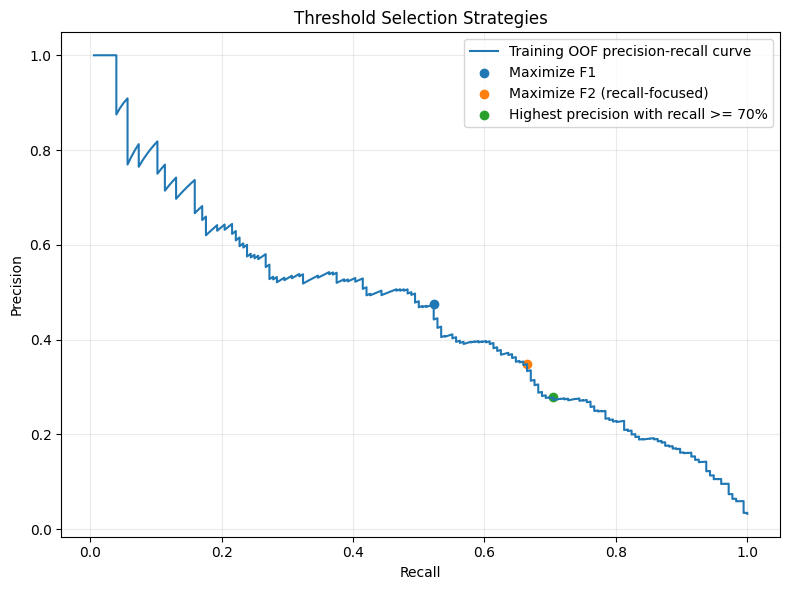

Saved threshold strategy comparison.
These are training OOF estimates, not final test-set performance.


In [59]:

# CELL 58B: Compare F1, F2 and Recall-Focused Thresholds

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    fbeta_score,
    precision_score,
    recall_score,
    f1_score
)

# Reuse training-only out-of-fold probabilities from Cell 58
if "oof_probabilities" not in globals():
    raise ValueError("Run Cell 58 first.")

y_oof = np.asarray(y_train, dtype=int)
oof_prob = np.asarray(oof_probabilities)

precision, recall, thresholds = precision_recall_curve(
    y_oof, oof_prob
)

# Threshold arrays align with precision[:-1] and recall[:-1]
p = precision[:-1]
r = recall[:-1]

f1_scores = (
    2 * p * r / np.maximum(p + r, 1e-12)
)

# F2 gives recall more weight than precision
f2_scores = (
    5 * p * r / np.maximum(4 * p + r, 1e-12)
)

# Select threshold maximizing F1
f1_idx = int(np.argmax(f1_scores))

# Select threshold maximizing F2
f2_idx = int(np.argmax(f2_scores))

# Select highest precision among thresholds meeting recall >= 70%
eligible = np.where(r >= 0.70)[0]

if len(eligible):
    recall_idx = int(eligible[np.argmax(p[eligible])])
else:
    recall_idx = None

rows = []

for strategy, idx in [
    ("Maximize F1", f1_idx),
    ("Maximize F2 (recall-focused)", f2_idx)
]:
    rows.append({
        "Strategy": strategy,
        "Threshold": float(thresholds[idx]),
        "OOF Precision": float(p[idx]),
        "OOF Recall": float(r[idx]),
        "OOF F1": float(f1_scores[idx]),
        "OOF F2": float(f2_scores[idx])
    })

if recall_idx is not None:
    rows.append({
        "Strategy": "Highest precision with recall >= 70%",
        "Threshold": float(thresholds[recall_idx]),
        "OOF Precision": float(p[recall_idx]),
        "OOF Recall": float(r[recall_idx]),
        "OOF F1": float(f1_scores[recall_idx]),
        "OOF F2": float(f2_scores[recall_idx])
    })

threshold_comparison = pd.DataFrame(rows)

print("TRAINING OOF THRESHOLD COMPARISON")
display(threshold_comparison.round(4))

# Visualize precision-recall trade-off
plt.figure(figsize=(8, 6))
plt.plot(r, p, label="Training OOF precision-recall curve")

for _, row in threshold_comparison.iterrows():
    plt.scatter(
        row["OOF Recall"],
        row["OOF Precision"],
        label=row["Strategy"]
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Threshold Selection Strategies")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Save diagnostic results
from pathlib import Path

PROCESSED_DIR = Path("/content/finsight_ai/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

threshold_comparison.to_csv(
    PROCESSED_DIR / "distress_threshold_strategy_comparison.csv",
    index=False
)

print("Saved threshold strategy comparison.")
print("These are training OOF estimates, not final test-set performance.")


FINAL HELD-OUT TEST METRICS


,Model,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Tuned XGBoost,0.4106,0.9663,0.7739,0.4808,0.5682,0.5208,0.9584,0.5176



Classification report:
              precision    recall  f1-score   support

Not Bankrupt       0.99      0.98      0.98      1320
    Bankrupt       0.48      0.57      0.52        44

    accuracy                           0.97      1364
   macro avg       0.73      0.77      0.75      1364
weighted avg       0.97      0.97      0.97      1364



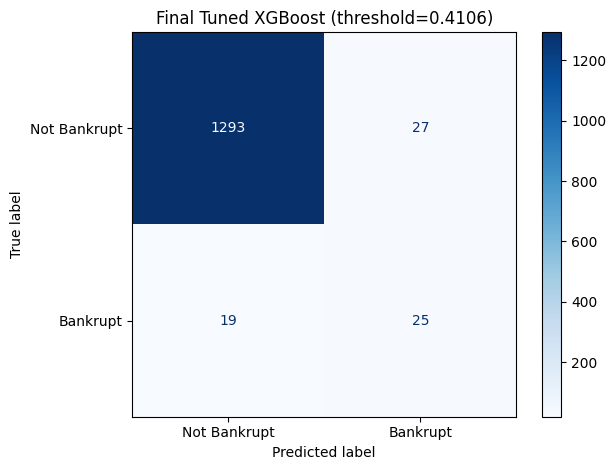


Saved final model, test metrics and test predictions.
Do not use these test results to choose another threshold.
This model is evaluated on Taiwanese company data, not validated Indian-company data.


In [60]:

# CELL 59: Final Evaluation on the Untouched Test Set

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json

from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay
)

# Validate prerequisites
required = ["search", "X_train", "y_train", "X_test", "y_test", "final_threshold"]
missing = [name for name in required if name not in globals()]
if missing:
    raise ValueError(
        f"Missing variables: {missing}. Run Cells 50, 56 and 58 successfully."
    )

# Fit the selected tuned model on training data only
final_model = clone(search.best_estimator_)
final_model.fit(X_train, np.asarray(y_train, dtype=int))

# Predict probabilities on held-out test set
y_test_array = np.asarray(y_test, dtype=int)
final_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected in Cell 58
final_predictions = (
    final_probabilities >= final_threshold
).astype(int)

# Calculate final metrics
final_test_metrics = pd.DataFrame([{
    "Model": "Tuned XGBoost",
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(y_test_array, final_predictions),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test_array, final_predictions
    ),
    "Precision": precision_score(
        y_test_array, final_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_array, final_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test_array, final_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test_array, final_probabilities),
    "PR-AUC": average_precision_score(
        y_test_array, final_probabilities
    )
}])

print("FINAL HELD-OUT TEST METRICS")
display(final_test_metrics.round(4))

print("\nClassification report:")
print(classification_report(
    y_test_array,
    final_predictions,
    target_names=["Not Bankrupt", "Bankrupt"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_array,
    final_predictions,
    display_labels=["Not Bankrupt", "Bankrupt"],
    cmap="Blues",
    values_format="d"
)
plt.title(f"Final Tuned XGBoost (threshold={final_threshold:.4f})")
plt.tight_layout()
plt.show()

# Save final model and results
PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
MODELS_DIR = PROJECT_DIR / "models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    final_model,
    MODELS_DIR / "financial_distress_final_model.joblib"
)

final_test_metrics.to_csv(
    PROCESSED_DIR / "financial_distress_final_test_metrics.csv",
    index=False
)

pd.DataFrame({
    "Actual_Bankrupt": y_test_array,
    "Predicted_Bankrupt": final_predictions,
    "Predicted_Risk_Probability": final_probabilities
}).to_csv(
    PROCESSED_DIR / "financial_distress_final_test_predictions.csv",
    index=False
)

print("\nSaved final model, test metrics and test predictions.")
print("Do not use these test results to choose another threshold.")
print("This model is evaluated on Taiwanese company data, not validated Indian-company data.")


FINANCIAL DISTRESS ASSESSMENT
--------------------------------
Test record index: 1244
Predicted distress probability: 0.04%
Decision threshold: 0.4106
Model classification: Lower predicted distress risk

This is a dataset record, not a named real company.

Top 15 factors influencing this prediction:


,Feature,Observed value,SHAP contribution,Direction,Absolute contribution
33,Quick Ratio,5.950000e-03,-1.30753,Pushes model output lower,1.30753
39,Borrowing dependency,3.775100e-01,-0.47032,Pushes model output lower,0.47032
18,Persistent EPS in the Last Four Seasons,2.214200e-01,-0.46570,Pushes model output lower,0.46570
45,Accounts Receivable Turnover,7.400000e-04,-0.40688,Pushes model output lower,0.40688
8,Non-industry income and expenditure/revenue,3.034700e-01,-0.39230,Pushes model output lower,0.39230
10,Operating Expense Rate,1.800000e-04,-0.37619,Pushes model output lower,0.37619
2,ROA(B) before interest and depreciation after...,5.522800e-01,-0.37238,Pushes model output lower,0.37238
73,Cash Turnover Rate,3.600000e+09,-0.36974,Pushes model output lower,0.36974
70,Current Asset Turnover Rate,1.100000e-04,-0.35312,Pushes model output lower,0.35312
71,Quick Asset Turnover Rate,9.710000e+09,-0.30694,Pushes model output lower,0.30694


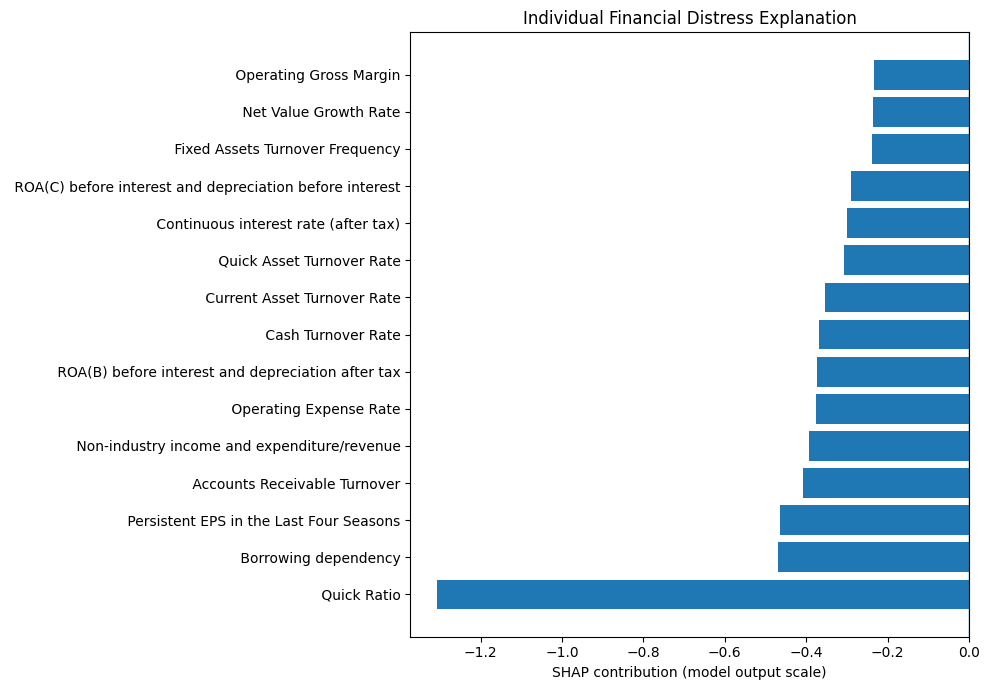


Saved individual explanation.
SHAP values explain model behaviour, not causal relationships. Risk probabilities are not guaranteed to be calibrated.


In [61]:

# CELL 60: Company-Level Financial Distress Explanation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from pathlib import Path

# Validate prerequisites
required = [
    "final_model", "X_test", "y_test",
    "final_threshold", "final_probabilities"
]

# Cell 59 may have created final_probabilities under this exact name.
# If not, the explanation below calculates probabilities directly.
missing = [
    name for name in ["final_model", "X_test", "final_threshold"]
    if name not in globals()
]
if missing:
    raise ValueError(
        f"Missing variables: {missing}. Run Cells 58 and 59 first."
    )

# Select a test record to explain
company_index = 0
company_record = X_test.iloc[[company_index]].copy()

risk_probability = float(
    final_model.predict_proba(company_record)[:, 1][0]
)

risk_prediction = int(risk_probability >= final_threshold)

risk_label = (
    "Elevated predicted distress risk"
    if risk_prediction == 1
    else "Lower predicted distress risk"
)

print("FINANCIAL DISTRESS ASSESSMENT")
print("--------------------------------")
print("Test record index:", company_record.index[0])
print(f"Predicted distress probability: {risk_probability:.2%}")
print(f"Decision threshold: {final_threshold:.4f}")
print("Model classification:", risk_label)
print("\nThis is a dataset record, not a named real company.")

# Transform features through preprocessing, if present
preprocessor_steps = list(final_model.steps[:-1])
classifier = final_model.named_steps["classifier"]

def transform_company_data(data):
    transformed = data.copy()
    for step_name, transformer in preprocessor_steps:
        transformed = transformer.transform(transformed)
    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()
    return np.asarray(transformed)

company_transformed = transform_company_data(company_record)

# Explain the selected record with SHAP
if classifier.__class__.__name__ in [
    "XGBClassifier", "RandomForestClassifier"
]:
    explainer = shap.TreeExplainer(classifier)
    shap_values = explainer.shap_values(company_transformed)
else:
    background_size = min(100, len(X_train))
    background = transform_company_data(
        X_train.sample(background_size, random_state=42)
    )
    explainer = shap.Explainer(
        classifier.predict_proba, background
    )
    shap_values = explainer(company_transformed)

# Normalize common SHAP output formats
if isinstance(shap_values, list):
    company_shap = np.asarray(
        shap_values[1] if len(shap_values) > 1 else shap_values[0]
    )
elif hasattr(shap_values, "values"):
    company_shap = np.asarray(shap_values.values)
else:
    company_shap = np.asarray(shap_values)

if company_shap.ndim == 3:
    company_shap = (
        company_shap[:, :, 1]
        if company_shap.shape[-1] > 1
        else company_shap[:, :, 0]
    )

company_shap = company_shap.reshape(1, -1)[0]

explanation_df = pd.DataFrame({
    "Feature": list(company_record.columns),
    "Observed value": company_record.iloc[0].to_numpy(),
    "SHAP contribution": company_shap
})

explanation_df["Direction"] = np.where(
    explanation_df["SHAP contribution"] > 0,
    "Pushes model output higher",
    "Pushes model output lower"
)

explanation_df["Absolute contribution"] = (
    explanation_df["SHAP contribution"].abs()
)

explanation_df = explanation_df.sort_values(
    "Absolute contribution", ascending=False
)

print("\nTop 15 factors influencing this prediction:")
display(explanation_df.head(15).round(5))

# Visualize the strongest contributors
plot_df = explanation_df.head(15).sort_values(
    "SHAP contribution"
)

plt.figure(figsize=(10, 7))
plt.barh(
    plot_df["Feature"],
    plot_df["SHAP contribution"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("SHAP contribution (model output scale)")
plt.title("Individual Financial Distress Explanation")
plt.tight_layout()
plt.show()

# Save the explanation
PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

explanation_df.to_csv(
    PROCESSED_DIR / "individual_distress_explanation.csv",
    index=False
)

print("\nSaved individual explanation.")
print(
    "SHAP values explain model behaviour, not causal relationships. "
    "Risk probabilities are not guaranteed to be calibrated."
)


In [62]:

# CELL 61: Validate RAG Retrieval and Source-Page Citations

import re
import pandas as pd
from pathlib import Path

# Check that the annual-report chunks exist
if "chunks_df" not in globals():
    raise ValueError(
        "chunks_df is missing. Run the annual-report extraction and chunking cells first."
    )

if "retrieve_financial_context" not in globals():
    raise ValueError(
        "retrieve_financial_context() is missing. Run the retrieval cell first."
    )

PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Inspect chunk columns to support the existing notebook schema
print("Chunk columns:", list(chunks_df.columns))
display(chunks_df.head(2))

# Choose a document text column from the known notebook schema
text_col = next(
    (c for c in ["chunk_text", "text", "content"] if c in chunks_df.columns),
    None
)
page_col = next(
    (c for c in ["page", "page_number", "page_num"] if c in chunks_df.columns),
    None
)
doc_col = next(
    (c for c in ["document", "source", "filename"] if c in chunks_df.columns),
    None
)

if text_col is None:
    raise ValueError(
        "Could not identify chunk text column. Check the displayed columns and update text_col."
    )

# Test queries that should be answerable from an annual report
test_questions = [
    "What are the company's main business segments?",
    "What risks does the company discuss?",
    "What does the report say about revenue and profitability?",
    "What are the company's capital expenditure or investment priorities?",
    "What does the report say about sustainability?"
]

validation_rows = []

for question in test_questions:
    print("\n" + "=" * 90)
    print("QUESTION:", question)

    # Retrieve the top passages
    retrieved = retrieve_financial_context(question, top_k=5)

    # Support either a DataFrame or list-like retrieval output
    if isinstance(retrieved, pd.DataFrame):
        retrieved_df = retrieved.copy()
    else:
        retrieved_df = pd.DataFrame(retrieved)

    print("\nRetrieved passages:")
    if retrieved_df.empty:
        print("No passages returned.")
        validation_rows.append({
            "Question": question,
            "Retrieved passages": 0,
            "Has text": False,
            "Has source metadata": False,
            "Manual evidence review": "Needs review"
        })
        continue

    display(retrieved_df.head(5))

    # Identify the returned text and source columns
    retrieved_text_col = next(
        (
            c for c in ["chunk_text", "text", "content"]
            if c in retrieved_df.columns
        ),
        None
    )
    retrieved_page_col = next(
        (
            c for c in ["page", "page_number", "page_num"]
            if c in retrieved_df.columns
        ),
        None
    )
    retrieved_doc_col = next(
        (
            c for c in ["document", "source", "filename"]
            if c in retrieved_df.columns
        ),
        None
    )

    has_text = retrieved_text_col is not None and retrieved_df[
        retrieved_text_col
    ].fillna("").astype(str).str.strip().ne("").any()

    has_source = (
        retrieved_page_col is not None or retrieved_doc_col is not None
    )

    validation_rows.append({
        "Question": question,
        "Retrieved passages": len(retrieved_df),
        "Has text": bool(has_text),
        "Has source metadata": bool(has_source),
        "Manual evidence review": "Needs manual verification"
    })

# Create a review checklist rather than claiming automatic correctness
validation_df = pd.DataFrame(validation_rows)

print("\nRETRIEVAL VALIDATION SUMMARY")
display(validation_df)

validation_df.to_csv(
    PROCESSED_DIR / "rag_retrieval_validation.csv",
    index=False
)

# Create a page-level audit worksheet from source chunks
audit_cols = [c for c in [doc_col, page_col, text_col] if c is not None]
audit_df = chunks_df[audit_cols].copy()

rename_map = {
    text_col: "Retrieved text"
}
if doc_col:
    rename_map[doc_col] = "Source document"
if page_col:
    rename_map[page_col] = "Source page"

audit_df = audit_df.rename(columns=rename_map)
audit_df["Evidence checked manually"] = ""
audit_df["Citation correct"] = ""
audit_df["Notes"] = ""

audit_df.to_csv(
    PROCESSED_DIR / "rag_citation_audit_worksheet.csv",
    index=False
)

print("\nSaved:")
print(PROCESSED_DIR / "rag_retrieval_validation.csv")
print(PROCESSED_DIR / "rag_citation_audit_worksheet.csv")
print(
    "\nImportant: successful retrieval and source metadata do not prove "
    "that an answer is correct. Open the cited pages and verify the evidence."
)


Chunk columns: ['document', 'page', 'chunk_id', 'text']


,document,page,chunk_id,text
0,Reliance_Annual_Report_2024_25.pdf,1,Reliance_Annual_Report_2024_25.pdf_p1_c1,Integrated Annual Report 2024-25 Realising Asp...
1,Reliance_Annual_Report_2024_25.pdf,2,Reliance_Annual_Report_2024_25.pdf_p2_c1,TABLE OF CONTENTS REPORTING SUITE 2024-25 RIL’...



QUESTION: What are the company's main business segments?

Retrieved passages:


,document,page,chunk_id,text,similarity
0,Reliance_Annual_Report_2024_25.pdf,130,Reliance_Annual_Report_2024_25.pdf_p130_c2,"l and Gas, Retail and Digital Services. The a...",0.556204
1,Reliance_Annual_Report_2024_25.pdf,130,Reliance_Annual_Report_2024_25.pdf_p130_c8,nd production of crude oil and natural gas. - ...,0.549818
2,Reliance_Annual_Report_2024_25.pdf,133,Reliance_Annual_Report_2024_25.pdf_p133_c7,Incorporation Proportion of Ownership Interest...,0.526177
3,Reliance_Annual_Report_2024_25.pdf,130,Reliance_Annual_Report_2024_25.pdf_p130_c1,Notes to the Consolidated Financial Statements...,0.512986
4,Reliance_Annual_Report_2024_25.pdf,40,Reliance_Annual_Report_2024_25.pdf_p40_c7,"Disney”), by the transfer of the media and Jio...",0.507039



QUESTION: What risks does the company discuss?

Retrieved passages:


...


QUESTION: What does the report say about sustainability?

Retrieved passages:


,document,page,chunk_id,text,similarity
0,Reliance_Annual_Report_2024_25.pdf,23,Reliance_Annual_Report_2024_25.pdf_p23_c9,ether the other information is materially inco...,0.613463
1,Reliance_Annual_Report_2024_25.pdf,23,Reliance_Annual_Report_2024_25.pdf_p23_c7,"lity Information may be materially misstated, ...",0.578487
2,Reliance_Annual_Report_2024_25.pdf,22,Reliance_Annual_Report_2024_25.pdf_p22_c11,ssurance about whether the Identified Sustaina...,0.573391
3,Reliance_Annual_Report_2024_25.pdf,2,Reliance_Annual_Report_2024_25.pdf_p2_c1,TABLE OF CONTENTS REPORTING SUITE 2024-25 RIL’...,0.570248
4,Reliance_Annual_Report_2024_25.pdf,23,Reliance_Annual_Report_2024_25.pdf_p23_c6,"s of the engagement, in performing the procedu...",0.563137



RETRIEVAL VALIDATION SUMMARY


,Question,Retrieved passages,Has text,Has source metadata,Manual evidence review
0,What are the company's main business segments?,5,True,True,Needs manual verification
1,What risks does the company discuss?,5,True,True,Needs manual verification
2,What does the report say about revenue and pro...,5,True,True,Needs manual verification
3,What are the company's capital expenditure or ...,5,True,True,Needs manual verification
4,What does the report say about sustainability?,5,True,True,Needs manual verification



Saved:
/content/finsight_ai/processed/rag_retrieval_validation.csv
/content/finsight_ai/processed/rag_citation_audit_worksheet.csv

Important: successful retrieval and source metadata do not prove that an answer is correct. Open the cited pages and verify the evidence.


In [63]:

# CELL 62: Financial Data Quality and Trend Verification

import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Check that financial data exists
if "financial_data" not in globals():
    raise ValueError(
        "financial_data is missing. Run the financial data preparation cell first."
    )

df = financial_data.copy()

required_columns = [
    "company", "financial_year", "statement_type",
    "metric", "value", "unit", "document",
    "page", "verification_status"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required financial data columns: {missing_columns}"
    )

# Normalize types
df["value"] = pd.to_numeric(df["value"], errors="coerce")
df["financial_year"] = df["financial_year"].astype(str).str.strip()
df["verification_status"] = (
    df["verification_status"].astype(str).str.lower().str.strip()
)

# 1. General quality checks
print("FINANCIAL DATA QUALITY REPORT")
print("=" * 60)
print("Total financial records:", len(df))
print("Missing numeric values:", int(df["value"].isna().sum()))
print("Missing company names:", int(df["company"].isna().sum()))
print("Missing source documents:", int(df["document"].isna().sum()))
print("Missing page references:", int(df["page"].isna().sum()))
print("Verification status counts:")
display(df["verification_status"].value_counts(dropna=False).to_frame("records"))

# Check duplicate keys
key_columns = [
    "company", "financial_year", "statement_type", "metric"
]
duplicate_mask = df.duplicated(subset=key_columns, keep=False)

print("\nRecords with duplicate company/year/statement/metric keys:",
      int(duplicate_mask.sum()))

if duplicate_mask.any():
    display(df.loc[duplicate_mask].sort_values(key_columns).head(20))

# 2. Check for records marked verified without source metadata
verified_mask = df["verification_status"].eq("verified")

missing_evidence_mask = (
    df["document"].isna()
    | df["document"].astype(str).str.strip().eq("")
    | df["page"].isna()
)

unsubstantiated_verified = df[verified_mask & missing_evidence_mask]

print("\nRecords marked verified but missing document/page evidence:",
      len(unsubstantiated_verified))

if not unsubstantiated_verified.empty:
    display(unsubstantiated_verified)

# 3. Create a manual source verification worksheet
audit_df = df.copy()
audit_df["Source figure checked"] = ""
audit_df["Unit checked"] = ""
audit_df["Page checked"] = ""
audit_df["Reviewer notes"] = ""

audit_path = PROCESSED_DIR / "financial_data_verification_worksheet.csv"
audit_df.to_csv(audit_path, index=False)

# 4. Check the historical trend data, if available
if "revenue" in globals() and "profit" in globals() and "years" in globals():
    trend_df = pd.DataFrame({
        "Financial Year": years,
        "Revenue": revenue,
        "Profit": profit
    })

    trend_df["Revenue"] = pd.to_numeric(
        trend_df["Revenue"], errors="coerce"
    )
    trend_df["Profit"] = pd.to_numeric(
        trend_df["Profit"], errors="coerce"
    )

    trend_df["Revenue YoY Growth (%)"] = (
        trend_df["Revenue"].pct_change() * 100
    )
    trend_df["Profit YoY Growth (%)"] = (
        trend_df["Profit"].pct_change() * 100
    )
    trend_df["Profit Margin (%)"] = (
        trend_df["Profit"] / trend_df["Revenue"] * 100
    )

    print("\nHISTORICAL TREND CALCULATIONS")
    display(trend_df.round(2))

    # Flag unusual changes for manual review, not automatic rejection
    trend_df["Revenue change needs review"] = (
        trend_df["Revenue YoY Growth (%)"].abs() > 50
    )
    trend_df["Profit change needs review"] = (
        trend_df["Profit YoY Growth (%)"].abs() > 50
    )

    print("\nLarge year-on-year changes requiring source review:")
    review_rows = trend_df[
        trend_df["Revenue change needs review"]
        | trend_df["Profit change needs review"]
    ]
    display(review_rows.round(2))

    trend_df.to_csv(
        PROCESSED_DIR / "financial_trend_verification.csv",
        index=False
    )
else:
    print(
        "\nHistorical variables years, revenue, profit were not found. "
        "The general data audit was completed; run the historical trend cell "
        "or adapt the variable names to your notebook."
    )

print("\nSaved verification worksheet:")
print(audit_path)
print(
    "\nReminder: 'verified' should mean checked against an authoritative source, "
    "not merely entered into the notebook."
)


FINANCIAL DATA QUALITY REPORT
Total financial records: 20
Missing numeric values: 0
Missing company names: 0
Missing source documents: 0
Missing page references: 0
Verification status counts:


,records
verification_status,
verified,20



Records with duplicate company/year/statement/metric keys: 0

Records marked verified but missing document/page evidence: 0

HISTORICAL TREND CALCULATIONS


,Financial Year,Revenue,Profit,Revenue YoY Growth (%),Profit YoY Growth (%),Profit Margin (%)
0,2015-16,1071174,81309,NaN,NaN,7.59
1,2016-17,1071174,81309,0.0,0.0,7.59
2,2017-18,1071174,81309,0.0,0.0,7.59
3,2018-19,1071174,81309,0.0,0.0,7.59
4,2019-20,1071174,81309,0.0,0.0,7.59
5,2020-21,1071174,81309,0.0,0.0,7.59
6,2021-22,1071174,81309,0.0,0.0,7.59
7,2022-23,1071174,81309,0.0,0.0,7.59
8,2023-24,1071174,81309,0.0,0.0,7.59
9,2024-25,1071174,81309,0.0,0.0,7.59



Large year-on-year changes requiring source review:


,Financial Year,Revenue,Profit,Revenue YoY Growth (%),Profit YoY Growth (%),Profit Margin (%),Revenue change needs review,Profit change needs review



Saved verification worksheet:
/content/finsight_ai/processed/financial_data_verification_worksheet.csv

Reminder: 'verified' should mean checked against an authoritative source, not merely entered into the notebook.


In [64]:

# CELL 63: Unified FinSight AI Evaluation Report

import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime

PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
MODELS_DIR = PROJECT_DIR / "models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

evaluation_rows = []

def add_metric(component, metric, value, source, interpretation=""):
    evaluation_rows.append({
        "Component": component,
        "Metric": metric,
        "Value": value,
        "Source": source,
        "Interpretation": interpretation
    })

# --------------------------------------------------
# 1. Sentiment analysis evaluation
# --------------------------------------------------
sentiment_path = PROCESSED_DIR / "sentiment_model_evaluation.csv"

if sentiment_path.exists():
    sentiment_df = pd.read_csv(sentiment_path)
    print("Sentiment evaluation loaded:")
    display(sentiment_df.head(10))

    for _, row in sentiment_df.iterrows():
        model_name = str(row.get("Model", row.get("model", "Sentiment model")))

        for metric_col in sentiment_df.columns:
            if metric_col.lower() in [
                "accuracy", "macro f1", "macro_f1",
                "macro precision", "macro_precision",
                "macro recall", "macro_recall"
            ]:
                add_metric(
                    "Sentiment Analysis",
                    f"{model_name} - {metric_col}",
                    row[metric_col],
                    sentiment_path.name,
                    "Check evaluation split and dataset overlap before reporting."
                )
else:
    print("Sentiment evaluation CSV not found. Run the sentiment evaluation cell.")

# --------------------------------------------------
# 2. Financial distress model evaluation
# --------------------------------------------------
distress_path = PROCESSED_DIR / "financial_distress_final_test_metrics.csv"

if distress_path.exists():
    distress_metrics = pd.read_csv(distress_path)
    print("\nFinal distress-model metrics:")
    display(distress_metrics)

    for _, row in distress_metrics.iterrows():
        for metric_col in distress_metrics.columns:
            if metric_col != "Model":
                add_metric(
                    "Financial Distress Prediction",
                    metric_col,
                    row[metric_col],
                    distress_path.name,
                    "Held-out Taiwanese bankruptcy benchmark; not validated on Indian firms."
                )
elif "final_test_metrics" in globals():
    for _, row in final_test_metrics.iterrows():
        for metric_col in final_test_metrics.columns:
            if metric_col != "Model":
                add_metric(
                    "Financial Distress Prediction",
                    metric_col,
                    row[metric_col],
                    "Current notebook variables",
                    "Confirm that this is the final held-out test evaluation."
                )
else:
    print("Final distress metrics not found. Run Cell 59 successfully.")

# --------------------------------------------------
# 3. RAG retrieval validation
# --------------------------------------------------
rag_path = PROCESSED_DIR / "rag_retrieval_validation.csv"

if rag_path.exists():
    rag_df = pd.read_csv(rag_path)
    print("\nRAG retrieval validation:")
    display(rag_df)

    add_metric(
        "RAG",
        "Questions tested",
        len(rag_df),
        rag_path.name,
        "Small manual validation sample; expand before making broad claims."
    )

    if "Has source metadata" in rag_df.columns:
        source_rate = pd.to_numeric(
            rag_df["Has source metadata"], errors="coerce"
        ).mean()

        add_metric(
            "RAG",
            "Retrieved results with source metadata",
            round(float(source_rate), 4),
            rag_path.name,
            "Metadata availability does not prove citation correctness."
        )
else:
    print("RAG validation file not found. Run Cell 61.")

# --------------------------------------------------
# 4. Financial data quality
# --------------------------------------------------
financial_audit_path = (
    PROCESSED_DIR / "financial_data_verification_worksheet.csv"
)

if financial_audit_path.exists():
    financial_audit = pd.read_csv(financial_audit_path)

    add_metric(
        "Financial Data",
        "Records audited",
        len(financial_audit),
        financial_audit_path.name,
        "Source-level verification still requires reviewer confirmation."
    )

    if "verification_status" in financial_audit.columns:
        status = financial_audit["verification_status"].astype(str).str.lower()
        verified_fraction = status.eq("verified").mean()

        add_metric(
            "Financial Data",
            "Records labelled verified",
            round(float(verified_fraction), 4),
            financial_audit_path.name,
            "Verify each figure against its original authoritative source."
        )
else:
    print("Financial verification worksheet not found. Run Cell 62.")

# --------------------------------------------------
# 5. Consolidated report
# --------------------------------------------------
evaluation_df = pd.DataFrame(evaluation_rows)

evaluation_csv = PROCESSED_DIR / "finsight_ai_unified_evaluation.csv"
evaluation_df.to_csv(evaluation_csv, index=False)

report_path = PROJECT_DIR / "FinSight_AI_Evaluation_Report.md"

report_lines = [
    "# FinSight AI: Evaluation Report",
    "",
    f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
    "",
    "## Project components",
    "",
    "- Financial sentiment analysis",
    "- Annual report retrieval and question answering",
    "- Financial ratio and trend analysis",
    "- Financial distress prediction",
    "- Explainability using SHAP",
    "",
    "## Consolidated evaluation results",
    "",
    evaluation_df.to_markdown(index=False) if not evaluation_df.empty
    else "No evaluation metrics were found. Run the component evaluation cells.",
    "",
    "## Important limitations",
    "",
    "1. The bankruptcy benchmark uses Taiwanese company data and does not establish "
    "performance on Indian companies.",
    "2. Financial values must be verified against their original authoritative sources.",
    "3. Retrieval scores and source metadata alone do not prove that generated answers "
    "are factually correct.",
    "4. Sentiment results may be optimistic if the evaluation data overlaps with "
    "the data used to fine-tune the pretrained model.",
    "5. Reported results must match the exact data split, model version, and threshold used.",
    "",
    "## Reproducibility",
    "",
    "The saved component-level CSV files should be retained alongside the notebook. "
    "Run the notebook from a clean runtime before final submission."
]

report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("\nUNIFIED EVALUATION TABLE")
display(evaluation_df)

print("\nSaved files:")
print(evaluation_csv)
print(report_path)


Sentiment evaluation loaded:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,TF-IDF + Logistic Regression,0.722107,0.667625,0.686664,0.675833
1,FinBERT,0.877066,0.842840,0.904878,0.868305



Final distress-model metrics:


,Model,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Tuned XGBoost,0.410613,0.966276,0.773864,0.480769,0.568182,0.520833,0.958437,0.517607



RAG retrieval validation:


,Question,Retrieved passages,Has text,Has source metadata,Manual evidence review
0,What are the company's main business segments?,5,True,True,Needs manual verification
1,What risks does the company discuss?,5,True,True,Needs manual verification
2,What does the report say about revenue and pro...,5,True,True,Needs manual verification
3,What are the company's capital expenditure or ...,5,True,True,Needs manual verification
4,What does the report say about sustainability?,5,True,True,Needs manual verification



UNIFIED EVALUATION TABLE


,Component,Metric,Value,Source,Interpretation
0,Sentiment Analysis,TF-IDF + Logistic Regression - Accuracy,0.722107,sentiment_model_evaluation.csv,Check evaluation split and dataset overlap bef...
1,Sentiment Analysis,TF-IDF + Logistic Regression - Macro Precision,0.667625,sentiment_model_evaluation.csv,Check evaluation split and dataset overlap bef...
2,Sentiment Analysis,TF-IDF + Logistic Regression - Macro Recall,0.686664,sentiment_model_evaluation.csv,Check evaluation split and dataset overlap bef...
3,Sentiment Analysis,TF-IDF + Logistic Regression - Macro F1,0.675833,sentiment_model_evaluation.csv,Check evaluation split and dataset overlap bef...
4,Sentiment Analysis,FinBERT - Accuracy,0.877066,sentiment_model_evaluation.csv,Check evaluation split and dataset overlap bef...
5,Sentiment Analysis,FinBERT - Macro Precision,0.842840,sentiment_model_evaluation.csv,Check evaluation split and dataset overlap bef...
6,Sentiment Analysis,FinBERT - Macro Recall,0.904878,sentiment_model_evaluation.csv,Check evaluation split and dataset overlap bef...
7,Sentiment Analysis,FinBERT - Macro F1,0.868305,sentiment_model_evaluation.csv,Check evaluation split and dataset overlap bef...
8,Financial Distress Prediction,Threshold,0.410613,financial_distress_final_test_metrics.csv,Held-out Taiwanese bankruptcy benchmark; not v...
9,Financial Distress Prediction,Accuracy,0.966276,financial_distress_final_test_metrics.csv,Held-out Taiwanese bankruptcy benchmark; not v...



Saved files:
/content/finsight_ai/processed/finsight_ai_unified_evaluation.csv
/content/finsight_ai/FinSight_AI_Evaluation_Report.md


In [65]:

# CELL 64: Package FinSight AI Submission Artifacts

from pathlib import Path
import zipfile
import json
import hashlib
from datetime import datetime

PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
MODELS_DIR = PROJECT_DIR / "models"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# Find reports saved by previous cells
possible_reports = [
    Path("/content/finsight_ai/FinSight_AI_Evaluation_Report.md"),
    Path("/content/FinSight_AI_Evaluation_Report.md"),
    PROJECT_DIR / "README.md"
]

# Collect useful project artifacts
artifact_paths = []

for folder in [PROCESSED_DIR, MODELS_DIR]:
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file():
                artifact_paths.append(path)

for path in possible_reports:
    if path.exists() and path.is_file():
        artifact_paths.append(path)

# Include the main notebook if it was explicitly saved in the project directory
for path in PROJECT_DIR.glob("*.ipynb"):
    artifact_paths.append(path)

# Remove duplicates and exclude the output ZIP itself
artifact_paths = sorted({
    path.resolve()
    for path in artifact_paths
    if path.is_file()
    and path.name != "FinSight_AI_Submission.zip"
})

if not artifact_paths:
    raise ValueError(
        "No artifacts were found. Run the preceding model and evaluation cells first."
    )

# Build a manifest with checksums
manifest = []

for path in artifact_paths:
    try:
        relative_path = str(path.relative_to(PROJECT_DIR.resolve()))
    except ValueError:
        relative_path = str(path)

    digest = hashlib.sha256(path.read_bytes()).hexdigest()

    manifest.append({
        "file": relative_path,
        "size_bytes": path.stat().st_size,
        "sha256": digest
    })

manifest_path = PROJECT_DIR / "submission_manifest.json"
manifest_path.write_text(
    json.dumps({
        "project": "FinSight AI",
        "created_at": datetime.now().isoformat(timespec="seconds"),
        "artifact_count": len(manifest),
        "artifacts": manifest
    }, indent=2),
    encoding="utf-8"
)

# Create a ZIP containing project artifacts and manifest
zip_path = Path("/content/FinSight_AI_Submission.zip")

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in artifact_paths:
        try:
            archive_name = str(path.relative_to(PROJECT_DIR.resolve()))
        except ValueError:
            archive_name = f"external_artifacts/{path.name}"

        archive.write(path, arcname=archive_name)

    archive.write(
        manifest_path,
        arcname="submission_manifest.json"
    )

# Verify ZIP integrity
with zipfile.ZipFile(zip_path, "r") as archive:
    bad_file = archive.testzip()
    archive_contents = archive.namelist()

if bad_file:
    raise RuntimeError(f"ZIP verification failed at: {bad_file}")

print("FinSight AI packaging complete.")
print("ZIP file:", zip_path)
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 ** 2), 2))
print("Artifacts packaged:", len(artifact_paths))
print("ZIP integrity check: passed")

print("\nIncluded files:")
for name in archive_contents:
    print("-", name)

print("\nDownload the ZIP using the next cell.")


FinSight AI packaging complete.
ZIP file: /content/FinSight_AI_Submission.zip
ZIP size (MB): 390.46
Artifacts packaged: 41
ZIP integrity check: passed

Included files:
- FinSight_AI_Evaluation_Report.md
- models/financial_distress_final_model.joblib
- models/financial_distress_final_threshold.json
- models/financial_distress_model_config.joblib
- models/financial_distress_model_tuned.joblib
- models/financial_distress_xgboost_tuned.joblib
- models/finbert/config.json
- models/finbert/model.safetensors
- models/finbert/tokenizer.json
- models/finbert/tokenizer_config.json
- models/model_info.json
- models/tfidf_sentiment_pipeline.joblib
- processed/annual_report_chunks.csv
- processed/annual_report_embeddings.npy
- processed/annual_report_pages.csv
- processed/distress_baseline_metrics.csv
- processed/distress_cross_validation.csv
- processed/distress_final_model_comparison.csv
- processed/distress_shap_feature_importance.csv
- processed/distress_threshold_diagnostic.csv
- processed/dis

In [66]:

# CELL 66: Install Streamlit and dashboard dependencies

%pip -q install streamlit plotly pandas numpy scikit-learn joblib shap xgboost

print("Dashboard dependencies installed.")
print("Next: create the Streamlit application file.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 55.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 49.8 MB/s eta 0:00:00
Dashboard dependencies installed.
Next: create the Streamlit application file.


In [67]:

# CELL 67: Create the FinSight AI Streamlit Dashboard

from pathlib import Path

PROJECT_DIR = Path("/content/finsight_ai")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

app_code = r'''
import json
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px
from pathlib import Path

PROJECT_DIR = Path("/content/finsight_ai")
PROCESSED_DIR = PROJECT_DIR / "processed"
MODELS_DIR = PROJECT_DIR / "models"

st.set_page_config(
    page_title="FinSight AI",
    page_icon="📊",
    layout="wide"
)

st.markdown("""
<style>
.main {background-color: #f5f7fb;}
[data-testid="stMetric"] {
    background: white;
    padding: 18px;
    border-radius: 12px;
    border: 1px solid #e4e8f0;
}
div.block-container {padding-top: 1.5rem;}
</style>
""", unsafe_allow_html=True)

st.title("📊 FinSight AI")
st.caption("Financial Document Intelligence, Analytics & Risk Assessment")

def load_csv(filename):
    path = PROCESSED_DIR / filename
    if path.exists():
        try:
            return pd.read_csv(path)
        except Exception:
            return pd.DataFrame()
    return pd.DataFrame()

def load_threshold():
    path = MODELS_DIR / "financial_distress_final_threshold.json"
    if path.exists():
        try:
            return json.loads(path.read_text())
        except Exception:
            pass

    path = MODELS_DIR / "financial_distress_model_config.joblib"
    if path.exists():
        try:
            return joblib.load(path)
        except Exception:
            pass

    return {}

# Load existing artifacts
distress_metrics = load_csv("financial_distress_final_test_metrics.csv")
sentiment_metrics = load_csv("sentiment_model_evaluation.csv")
financial_data = load_csv("financial_data_verification_worksheet.csv")
trend_data = load_csv("financial_trend_verification.csv")
rag_validation = load_csv("rag_retrieval_validation.csv")
shap_data = load_csv("distress_shap_feature_importance.csv")

tabs = st.tabs([
    "Overview",
    "Financial Trends",
    "Distress Prediction",
    "Sentiment Analysis",
    "Document Intelligence",
    "Project Evaluation"
])

# ----------------------------------------------------
# OVERVIEW
# ----------------------------------------------------
with tabs[0]:
    st.subheader("Project Overview")

    c1, c2, c3, c4 = st.columns(4)

    if not distress_metrics.empty:
        row = distress_metrics.iloc[0]
        c1.metric(
            "Distress Model PR-AUC",
            f"{float(row['PR-AUC']):.3f}"
            if "PR-AUC" in row.index and pd.notna(row["PR-AUC"])
            else "Unavailable"
        )
        c2.metric(
            "Distress Model ROC-AUC",
            f"{float(row['ROC-AUC']):.3f}"
            if "ROC-AUC" in row.index and pd.notna(row["ROC-AUC"])
            else "Unavailable"
        )
        c3.metric(
            "Test Recall",
            f"{float(row['Recall']):.1%}"
            if "Recall" in row.index and pd.notna(row["Recall"])
            else "Unavailable"
        )
    else:
        c1.metric("Distress Model PR-AUC", "Unavailable")
        c2.metric("Distress Model ROC-AUC", "Unavailable")
        c3.metric("Test Recall", "Unavailable")

    c4.metric(
        "Financial Records",
        f"{len(financial_data):,}" if not financial_data.empty else "Unavailable"
    )

    st.markdown("### System Components")
    st.write(
        "- Financial sentiment analysis using TF-IDF and FinBERT\n"
        "- Annual-report retrieval and question answering\n"
        "- Financial ratio and trend analysis\n"
        "- Financial distress prediction using machine learning\n"
        "- Model interpretation with SHAP"
    )

    st.info(
        "The distress model uses a Taiwanese bankruptcy benchmark. "
        "Its results are not validated for Indian companies."
    )

# ----------------------------------------------------
# FINANCIAL TRENDS
# ----------------------------------------------------
with tabs[1]:
    st.subheader("Financial Performance & Trends")

    if not trend_data.empty:
        st.dataframe(trend_data, use_container_width=True)

        numeric_candidates = [
            c for c in ["Revenue", "Profit"]
            if c in trend_data.columns
        ]

        if "Financial Year" in trend_data.columns and numeric_candidates:
            selected_metrics = st.multiselect(
                "Select financial metrics",
                numeric_candidates,
                default=numeric_candidates
            )

            if selected_metrics:
                plot_df = trend_data[
                    ["Financial Year"] + selected_metrics
                ].melt(
                    id_vars="Financial Year",
                    var_name="Metric",
                    value_name="Value"
                )
                fig = px.line(
                    plot_df,
                    x="Financial Year",
                    y="Value",
                    color="Metric",
                    markers=True,
                    title="Historical Financial Performance"
                )
                st.plotly_chart(fig, use_container_width=True)
    elif not financial_data.empty:
        st.write("Financial records loaded:")
        st.dataframe(financial_data, use_container_width=True)
        st.warning(
            "No prepared historical trend table was found. "
            "Run Cell 62 to create the trend verification file."
        )
    else:
        st.warning(
            "No financial trend data found. Run the financial data preparation "
            "and verification cells first."
        )

# ----------------------------------------------------
# DISTRESS PREDICTION
# ----------------------------------------------------
with tabs[2]:
    st.subheader("Financial Distress Prediction")

    model_path = MODELS_DIR / "financial_distress_final_model.joblib"
    threshold_config = load_threshold()
    threshold = float(threshold_config.get("threshold", 0.5))

    if not model_path.exists():
        st.warning(
            "The final distress model was not found. Run Cell 59 and confirm "
            "the saved model exists before using predictions."
        )
    else:
        try:
            model = joblib.load(model_path)
            st.caption(f"Saved decision threshold: {threshold:.4f}")

            st.write(
                "Upload a CSV containing the model's original input features. "
                "Use the same feature names and units as the training dataset. "
                "Do not include the target column 'Bankrupt'."
            )

            uploaded = st.file_uploader(
                "Upload company financial indicators (CSV)",
                type=["csv"],
                key="distress_upload"
            )

            if uploaded is not None:
                input_df = pd.read_csv(uploaded)

                feature_path = MODELS_DIR / "financial_distress_feature_names.joblib"
                if not feature_path.exists():
                    feature_path = MODELS_DIR / "financial_distress_model_config.joblib"

                expected_features = None
                if feature_path.exists():
                    saved_features = joblib.load(feature_path)
                    if isinstance(saved_features, list):
                        expected_features = saved_features
                    elif isinstance(saved_features, dict):
                        expected_features = saved_features.get("feature_names")

                if expected_features is None:
                    st.error(
                        "The expected feature schema is missing. "
                        "Save the model's training feature names before prediction."
                    )
                else:
                    missing_features = [
                        col for col in expected_features
                        if col not in input_df.columns
                    ]

                    extra_features = [
                        col for col in input_df.columns
                        if col not in expected_features
                    ]

                    if missing_features:
                        st.error(
                            f"Missing {len(missing_features)} required features: "
                            + ", ".join(missing_features[:10])
                        )
                    elif extra_features:
                        st.warning(
                            "Extra columns will be ignored: "
                            + ", ".join(extra_features[:10])
                        )

                    if not missing_features:
                        model_input = input_df[expected_features].copy()

                        for col in model_input.columns:
                            model_input[col] = pd.to_numeric(
                                model_input[col], errors="coerce"
                            )

                        if model_input.isna().all(axis=1).any():
                            st.error(
                                "At least one uploaded row has no usable numeric "
                                "feature values. Correct the file before prediction."
                            )
                        else:
                            probabilities = model.predict_proba(model_input)[:, 1]
                            predictions = (probabilities >= threshold).astype(int)

                            results = pd.DataFrame({
                                "Predicted distress probability": probabilities,
                                "Predicted class": np.where(
                                    predictions == 1,
                                    "Higher predicted risk",
                                    "Lower predicted risk"
                                )
                            })

                            st.dataframe(results, use_container_width=True)

                            st.download_button(
                                "Download predictions CSV",
                                data=results.to_csv(index=False).encode("utf-8"),
                                file_name="finsight_distress_predictions.csv",
                                mime="text/csv"
                            )

                            st.warning(
                                "These are benchmark-model predictions, not calibrated "
                                "Indian-company bankruptcy probabilities. Use only "
                                "records with compatible feature definitions and units."
                            )
        except Exception as e:
            st.error(f"Could not load or use the saved model: {e}")

# ----------------------------------------------------
# SENTIMENT
# ----------------------------------------------------
with tabs[3]:
    st.subheader("Financial Sentiment Analysis")

    if not sentiment_metrics.empty:
        st.dataframe(sentiment_metrics, use_container_width=True)
    else:
        st.warning(
            "Sentiment evaluation results were not found in processed/. "
            "Run the sentiment evaluation cells and save their metrics."
        )

    st.markdown("#### Analyse a financial statement")
    sentiment_text = st.text_area(
        "Paste a financial sentence or paragraph",
        placeholder="Enter a statement from a financial report..."
    )

    st.caption(
        "The interactive sentiment prediction will be connected once the "
        "sentiment model is saved as a reusable artifact."
    )

    if sentiment_text.strip():
        st.info(
            "Text entered. The dashboard currently displays saved evaluation "
            "results; it does not yet run live sentiment inference."
        )

# ----------------------------------------------------
# DOCUMENT INTELLIGENCE
# ----------------------------------------------------
with tabs[4]:
    st.subheader("Annual Report Document Search")

    chunks_path = PROCESSED_DIR / "annual_report_chunks.csv"
    if not chunks_path.exists():
        chunks_path = PROJECT_DIR / "documents" / "annual_report_chunks.csv"

    if chunks_path.exists():
        try:
            chunks = pd.read_csv(chunks_path)

            text_col = next(
                (c for c in ["chunk_text", "text", "content"] if c in chunks.columns),
                None
            )
            page_col = next(
                (c for c in ["page", "page_number", "page_num"] if c in chunks.columns),
                None
            )
            doc_col = next(
                (c for c in ["document", "source", "filename"] if c in chunks.columns),
                None
            )

            query = st.text_input(
                "Search annual-report passages",
                placeholder="e.g. capital expenditure, business risks, revenue"
            )

            if query and text_col:
                terms = [
                    t.lower() for t in query.split()
                    if len(t) > 2
                ]
                searchable = chunks[text_col].fillna("").astype(str).str.lower()

                scores = searchable.apply(
                    lambda text: sum(text.count(term) for term in terms)
                )

                results = chunks.loc[scores.sort_values(ascending=False).head(5).index].copy()
                results["Keyword relevance score"] = scores.loc[results.index]

                if results["Keyword relevance score"].max() == 0:
                    st.info("No passages matched the search terms.")
                else:
                    for _, row in results.sort_values(
                        "Keyword relevance score", ascending=False
                    ).iterrows():
                        source = str(row[doc_col]) if doc_col else "Source not recorded"
                        page = str(row[page_col]) if page_col else "Page not recorded"

                        with st.expander(f"{source} | Page {page}"):
                            st.write(str(row[text_col]))
                            st.caption(
                                "Keyword matching only. This is not the semantic "
                                "retriever or a generated, citation-validated answer."
                            )
            elif not text_col:
                st.error("Could not identify the text column in the chunk file.")
        except Exception as e:
            st.error(f"Could not read document chunks: {e}")
    else:
        st.warning(
            "Annual-report chunks CSV was not found. Save your chunk DataFrame "
            "to processed/annual_report_chunks.csv to enable this search panel."
        )

# ----------------------------------------------------
# EVALUATION
# ----------------------------------------------------
with tabs[5]:
    st.subheader("Evaluation & Data Quality")

    if not distress_metrics.empty:
        st.markdown("#### Final Distress Model Metrics")
        st.dataframe(distress_metrics, use_container_width=True)

    if not rag_validation.empty:
        st.markdown("#### RAG Retrieval Checks")
        st.dataframe(rag_validation, use_container_width=True)

    if not shap_data.empty:
        st.markdown("#### SHAP Feature Importance")
        st.dataframe(shap_data.head(20), use_container_width=True)

    if not financial_data.empty:
        st.markdown("#### Financial Data Verification Worksheet")
        st.dataframe(financial_data.head(100), use_container_width=True)

    st.caption(
        "FinSight AI is a research prototype. Results depend on data quality, "
        "evaluation methodology, source verification, and external validation."
    )
'''

app_path = PROJECT_DIR / "app.py"
app_path.write_text(app_code, encoding="utf-8")

print("Streamlit application created:")
print(app_path)
print("File size:", round(app_path.stat().st_size / 1024, 1), "KB")
print("Next: launch the dashboard from Colab.")


Streamlit application created:
/content/finsight_ai/app.py
File size: 15.1 KB
Next: launch the dashboard from Colab.


In [68]:

# CELL 68: Launch FinSight AI Dashboard in Google Colab

from pathlib import Path
import subprocess
import time
import requests
from google.colab import output

PROJECT_DIR = Path("/content/finsight_ai")
APP_FILE = PROJECT_DIR / "app.py"
PORT = 8501

if not APP_FILE.exists():
    raise FileNotFoundError(
        "app.py not found. Run Cell 67 first."
    )

# Stop an earlier Streamlit process on this port, if present
subprocess.run(
    ["bash", "-lc", "pkill -f 'streamlit run /content/finsight_ai/app.py' || true"],
    capture_output=True,
    text=True
)

# Start Streamlit
log_file = open("/content/finsight_ai/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", str(APP_FILE),
        "--server.port", str(PORT),
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--browser.gatherUsageStats", "false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Wait for the server to start
server_ready = False

for _ in range(30):
    try:
        response = requests.get(
            f"http://127.0.0.1:{PORT}/_stcore/health",
            timeout=2
        )
        if response.status_code == 200:
            server_ready = True
            break
    except Exception:
        time.sleep(2)

if server_ready:
    print("FinSight AI is running.")
    output.serve_kernel_port_as_window(PORT)
else:
    print("Streamlit did not start successfully.")
    print("Check the log below:")
    print(Path("/content/finsight_ai/streamlit.log").read_text()[-6000:])


FinSight AI is running.
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [69]:

# CELL 69: Check Streamlit and open the newer Colab viewer

import requests
from pathlib import Path
from google.colab import output

PORT = 8501

# Check whether Streamlit is responding
try:
    response = requests.get(
        f"http://127.0.0.1:{PORT}/_stcore/health",
        timeout=10
    )
    print("Health check:", response.status_code, response.text)

    if response.status_code == 200:
        print("Streamlit is running. Opening the updated viewer...")
        output.serve_kernel_port_as_iframe(PORT, height=850)
    else:
        print("Streamlit responded, but the health check was unsuccessful.")
except Exception as e:
    print("Could not connect to Streamlit:", repr(e))

# Show recent logs if available
log_path = Path("/content/finsight_ai/streamlit.log")
if log_path.exists():
    print("\nRecent Streamlit logs:")
    print(log_path.read_text()[-4000:])


Health check: 200 ok
Streamlit is running. Opening the updated viewer...


<IPython.core.display.Javascript object>


Recent Streamlit logs:
.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-10-23 13:41:19.677 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-usc1a1-2milcwnon4t7z-a.us-central1-1.prod.colab.dev, host=m-s-kkb-usc1a1-2milcwnon4t7z.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-10-23 13:41:23.040 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-usc1a1-2milcwnon4t7z-a.us-central1-1.prod.colab.dev, host=m-s-kkb-usc1a1-2milcwnon4t7z.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-10-23 13:41:28.231 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-usc1a1-2milcwnon4t7z-a.us-central1-1.prod.colab.dev, host=m-s-kkb-usc1a1-2milcwnon4t7z.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-10-23 13:41:31.996 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-usc1a1-2mi

In [70]:

# CELL 70: Diagnose a black dashboard

import requests
from pathlib import Path

url = "http://127.0.0.1:8501"

try:
    r = requests.get(url, timeout=10)
    print("HTTP status:", r.status_code)
    print("Response preview:", r.text[:500])
except Exception as e:
    print("Server connection failed:", repr(e))

log = Path("/content/finsight_ai/streamlit.log")
if log.exists():
    print("\n--- Streamlit log ---")
    print(log.read_text()[-6000:])


HTTP status: 200
Response preview: <!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Unless required by applicable law or agreed to in writing, software
 distributed under the License is distributed on an "AS IS" BASIS,
 WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or im

--- Streamlit log ---
ction with disallowed Origin or Host header: origin=https://8501-m-s-kkb-usc1a1-2milcwnon4t7z-a.us-central1-1.prod.colab.dev, host=m-s-kkb-usc1a1-2milcwnon4t7z.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-10-23 13:43:50.101 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-usc1a1-2milcwnon4t7z-a.us-central1-1.prod.colab.dev, host=m-s-kkb-usc1a1-2milcwnon4t7z.us-central1-a.c.co

In [71]:

# CELL 71: Fix Streamlit Host and WebSocket validation in Colab

import subprocess
import time
import requests
from pathlib import Path
from google.colab import output

APP = "/content/finsight_ai/app.py"
LOG = "/content/finsight_ai/streamlit.log"
PORT = 8501

# Stop the old Streamlit process
subprocess.run(
    ["bash", "-lc", "pkill -f '[s]treamlit run' || true"],
    capture_output=True,
    text=True
)
time.sleep(2)

# Restart with Colab-compatible server settings
with open(LOG, "w") as log_file:
    process = subprocess.Popen(
        [
            "streamlit", "run", APP,
            "--server.port=8501",
            "--server.address=0.0.0.0",
            "--server.headless=true",
            "--server.enableCORS=false",
            "--server.enableXsrfProtection=false",
            "--server.enableWebsocketCompression=false",
            "--browser.gatherUsageStats=false"
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

# Wait for server startup
for attempt in range(20):
    try:
        response = requests.get(
            f"http://127.0.0.1:{PORT}/_stcore/health",
            timeout=3
        )
        if response.status_code == 200:
            print("Streamlit server is healthy.")
            break
    except requests.RequestException:
        pass
    time.sleep(2)
else:
    print("Server startup failed. Recent logs:")
    print(Path(LOG).read_text()[-4000:])

# Open the updated Colab viewer
if response.status_code == 200:
    output.serve_kernel_port_as_iframe(PORT, height=850)


Streamlit server is healthy.


<IPython.core.display.Javascript object>